# Notebook 5: Data Preparation and Improvement





In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
DATA_DIR = "./data"


MADRID_TRAIN_PATH = f"{DATA_DIR}/madrid_train.parquet"


AMSTERDAM_DATA_PATH = f"{DATA_DIR}/amsterdam_data.parquet"

In [3]:
# ── Constants ──────────────────────────────────────────────────────────────────
BASE_BANDS = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']

# City-specific class 1/2 boundary year (Notebook 1, Section 1.4)
CLASS_EVENTS = {'Amsterdam': 1945, 'Madrid': 1960}

CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
CLASS_LABELS = {
    'Amsterdam': {1: 'Pre-1945',  2: '1945-1984', 3: '1984-2004', 4: '2004-2024'},
    'Madrid':    {1: 'Pre-1960',  2: '1960-1984', 3: '1984-2004', 4: '2004-2024'},
}

plt.rcParams['figure.dpi'] = 100

In [4]:
# ── Load training data ─────────────────────────────────────────────────────────
df = pd.read_parquet(MADRID_TRAIN_PATH)
print(f"Loaded: {len(df):,} rows x {df.shape[1]} columns")
print(f"City:      {df['city'].unique().tolist()}")
print(f"Years:     {df['year'].min()} - {df['year'].max()}  ({df['year'].nunique()} distinct years)")
print(f"Locations: {df.groupby(['px_key','py_key']).ngroups:,} unique geographic pixels")

# ── Derive age class from weighted_mean_year ───────────────────────────────────
def assign_age_class(data, events=CLASS_EVENTS):
    out = data.copy()
    out['age_class'] = pd.NA
    for city, ev in events.items():
        mask = out['city'] == city
        if mask.any():
            bins = [-np.inf, ev, 1984, 2004, np.inf]
            out.loc[mask, 'age_class'] = pd.cut(
                out.loc[mask, 'weighted_mean_year'],
                bins=bins, labels=[1, 2, 3, 4]
            ).astype('Int64')
    return out

df = assign_age_class(df)
print(f"\nAge class distribution (rows):")
for cls, n in df['age_class'].value_counts().sort_index().items():
    city = df['city'].iloc[0]
    lbl = CLASS_LABELS.get(city, CLASS_LABELS['Madrid']).get(int(cls), '')
    print(f"  Class {cls} ({lbl}): {n:,}")

Loaded: 3,172,765 rows x 48 columns
City:      ['Madrid']
Years:     1984 - 2025  (42 distinct years)
Locations: 76,263 unique geographic pixels

Age class distribution (rows):
  Class 1 (Pre-1960): 576,190
  Class 2 (1960-1984): 1,125,456
  Class 3 (1984-2004): 780,886
  Class 4 (2004-2024): 690,233


In [5]:
# Display all column names
print("MADRID DATASET COLUMNS")
print("=" * 50)

for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nTotal columns:", len(df.columns))

MADRID DATASET COLUMNS
1. pixel_id
2. city
3. year
4. px_key
5. py_key
6. pixel_x
7. pixel_y
8. row
9. col
10. coverage
11. usable_label
12. weighted_mean_year
13. Blue_1
14. Green_1
15. Red_1
16. NIR_1
17. SWIR1_1
18. SWIR2_1
19. QA_PIXEL_1
20. QA_RADSAT_1
21. doy_1
22. scene_id_1
23. dataset_1
24. qa_valid_1
25. Blue_2
26. Green_2
27. Red_2
28. NIR_2
29. SWIR1_2
30. SWIR2_2
31. QA_PIXEL_2
32. QA_RADSAT_2
33. doy_2
34. scene_id_2
35. dataset_2
36. qa_valid_2
37. Blue_3
38. Green_3
39. Red_3
40. NIR_3
41. SWIR1_3
42. SWIR2_3
43. QA_PIXEL_3
44. QA_RADSAT_3
45. doy_3
46. scene_id_3
47. dataset_3
48. qa_valid_3
49. age_class

Total columns: 49


In [6]:
# Examine the data types of all columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3172765 entries, 0 to 3172764
Data columns (total 49 columns):
 #   Column              Dtype  
---  ------              -----  
 0   pixel_id            str    
 1   city                str    
 2   year                int64  
 3   px_key              int32  
 4   py_key              int32  
 5   pixel_x             float32
 6   pixel_y             float32
 7   row                 int32  
 8   col                 int32  
 9   coverage            float32
 10  usable_label        bool   
 11  weighted_mean_year  float32
 12  Blue_1              float32
 13  Green_1             float32
 14  Red_1               float32
 15  NIR_1               float32
 16  SWIR1_1             float32
 17  SWIR2_1             float32
 18  QA_PIXEL_1          uint16 
 19  QA_RADSAT_1         uint16 
 20  doy_1               int16  
 21  scene_id_1          str    
 22  dataset_1           str    
 23  qa_valid_1          bool   
 24  Blue_2              float32
 25  Gr

In [7]:
# Display descriptive statistics
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
year,3172765.0,2.004560e+03,12.110280,1.984000e+03,1.994000e+03,2.005000e+03,2.015000e+03,2.025000e+03
px_key,3172765.0,1.473799e+04,150.327386,1.419400e+04,1.464700e+04,1.472500e+04,1.483700e+04,1.517100e+04
py_key,3172765.0,1.491815e+05,160.822077,1.487750e+05,1.490510e+05,1.491920e+05,1.493020e+05,1.496710e+05
pixel_x,3172765.0,4.421396e+05,4509.821289,4.258200e+05,4.394100e+05,4.417500e+05,4.451100e+05,4.551300e+05
pixel_y,3172765.0,4.475444e+06,4824.662109,4.463250e+06,4.471530e+06,4.475760e+06,4.479060e+06,4.490130e+06
row,3172765.0,4.945126e+02,160.822077,5.000000e+00,3.740000e+02,4.840000e+02,6.250000e+02,9.010000e+02
col,3172765.0,5.639864e+02,150.327386,2.000000e+01,4.730000e+02,5.510000e+02,6.630000e+02,9.970000e+02
coverage,3172765.0,5.040128e-01,0.250696,1.500000e-01,3.000000e-01,4.600000e-01,6.800000e-01,1.000000e+00
weighted_mean_year,3172765.0,1.980723e+03,25.295092,1.850000e+03,1.965000e+03,1.981000e+03,2.002049e+03,2.021000e+03
Blue_1,3172765.0,1.041215e+04,2206.543457,0.000000e+00,9.749780e+03,1.035645e+04,1.108935e+04,6.412600e+04


In [8]:
# Calculate missing values for every column
missing_summary = pd.DataFrame({
    'Missing_Values': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100)
})

# Sort columns by missing percentage
missing_summary = missing_summary.sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing_summary)

,Missing_Values,Missing_Percentage
pixel_id,0,0.0
city,0,0.0
year,0,0.0
px_key,0,0.0
py_key,0,0.0
pixel_x,0,0.0
pixel_y,0,0.0
row,0,0.0
col,0,0.0
coverage,0,0.0


In [9]:
# Count completely duplicated rows
duplicate_rows = df.duplicated().sum()

print("Completely duplicated rows:", duplicate_rows)
print("Percentage duplicated:", round(
    (duplicate_rows / len(df)) * 100, 4
), "%")

Completely duplicated rows: 0
Percentage duplicated: 0.0 %


In [10]:
# Check whether the same geographical pixel appears more than once in a year
duplicate_pixel_year = df.duplicated(
    subset=['px_key', 'py_key', 'year']
).sum()

print("Duplicate pixel-year records:", duplicate_pixel_year)

Duplicate pixel-year records: 0


In [11]:
duplicates = df[
    df.duplicated(
        subset=['px_key', 'py_key', 'year'],
        keep=False
    )
].sort_values(['px_key', 'py_key', 'year'])

display(duplicates)

,pixel_id,city,year,px_key,py_key,pixel_x,pixel_y,row,col,coverage,...,NIR_3,SWIR1_3,SWIR2_3,QA_PIXEL_3,QA_RADSAT_3,doy_3,scene_id_3,dataset_3,qa_valid_3,age_class


In [12]:
# Minimum and maximum observation years
print("First observation year:", df['year'].min())
print("Last observation year:", df['year'].max())
print("Number of distinct years:", df['year'].nunique())

First observation year: 1984
Last observation year: 2025
Number of distinct years: 42


In [13]:
# Count observations for each year
year_counts = df['year'].value_counts().sort_index()

display(year_counts.to_frame(name='Number_of_Records'))

,Number_of_Records
year,
1984,75145
1985,75532
1986,75351
1987,72838
1988,74641
1989,75381
1990,74662
1991,73936
1992,74710


In [14]:
# Generate the complete range of calendar years
start_year = df['year'].min()
end_year = df['year'].max()

all_years = range(start_year, end_year + 1)

# Identify missing years
missing_years = sorted(set(all_years) - set(df['year'].unique()))

# Display results
if missing_years:
    print(f"Missing observation years between {start_year} and {end_year}:")
    print(missing_years)
else:
    print(f"No calendar years are missing.")
    print(f"Observation period: {start_year} to {end_year}.")
    print(f"All calendar years from {start_year} to {end_year} are present.")

No calendar years are missing.
Observation period: 1984 to 2025.
All calendar years from 1984 to 2025 are present.


In [15]:
# Spectral columns
spectral_cols = [
    f'{band}_{slot}'
    for band in BASE_BANDS
    for slot in [1, 2, 3]
]

# Count zero values and extremely high values
for col in spectral_cols:
    zero_count = (df[col] == 0).sum()
    high_count = (df[col] > 30000).sum()

    print(
        f"{col:12} | "
        f"Zeros: {zero_count:8,} | "
        f"Above 30000: {high_count:8,}"
    )

Blue_1       | Zeros:       22 | Above 30000:    1,397
Blue_2       | Zeros:       20 | Above 30000:    1,126
Blue_3       | Zeros:       39 | Above 30000:   51,736
Green_1      | Zeros:        1 | Above 30000:      700
Green_2      | Zeros:        0 | Above 30000:      505
Green_3      | Zeros:        0 | Above 30000:   45,129
Red_1        | Zeros:        0 | Above 30000:    1,475
Red_2        | Zeros:        0 | Above 30000:    1,081
Red_3        | Zeros:        0 | Above 30000:   49,927
NIR_1        | Zeros:        0 | Above 30000:      673
NIR_2        | Zeros:        0 | Above 30000:      708
NIR_3        | Zeros:        0 | Above 30000:   50,026
SWIR1_1      | Zeros:        0 | Above 30000:    2,651
SWIR1_2      | Zeros:        0 | Above 30000:    2,469
SWIR1_3      | Zeros:        0 | Above 30000:    7,718
SWIR2_1      | Zeros:        0 | Above 30000:    1,608
SWIR2_2      | Zeros:        0 | Above 30000:    1,434
SWIR2_3      | Zeros:        0 | Above 30000:    2,104


In [16]:
for slot in [1, 2, 3]:
    col = f'QA_RADSAT_{slot}'

    print(f"\n{col}")
    print(df[col].value_counts().sort_index())


QA_RADSAT_1
QA_RADSAT_1
0      3167220
1          790
2            9
3            7
4          782
5          264
6           38
7          517
8          166
9            1
10           1
12           1
14           1
15           7
16        1803
17         122
20          90
21           9
22           1
23          49
24           1
27           1
29           2
31           5
32           3
34           1
60           1
64         203
65           2
68           9
71           4
79           1
80         386
81          24
82           1
83           1
84          81
85           8
86           8
87          38
88           4
92           6
93           6
94           1
95          34
96          26
97           1
98           1
99           1
112          3
116          1
123          1
124          4
126          1
127          7
256         10
Name: count, dtype: int64

QA_RADSAT_2
QA_RADSAT_2
0      3168610
1          685
2           24
3            4
4          399
5        

In [17]:
# Get one record per geographical pixel
pixel_data = df.drop_duplicates(subset=['px_key', 'py_key'])

print("\nOriginal age class distribution (unique geographical pixels):")

for cls, n in pixel_data['age_class'].value_counts().sort_index().items():
    city = df['city'].iloc[0]
    lbl = CLASS_LABELS.get(city, CLASS_LABELS['Madrid']).get(int(cls), '')
    percentage = (n / len(pixel_data)) * 100

    print(f"  Class {cls} ({lbl}): {n:,} pixels ({percentage:.2f}%)")

print(f"\nTotal unique geographical pixels: {len(pixel_data):,}")


Original age class distribution (unique geographical pixels):
  Class 1 (Pre-1960): 13,794 pixels (18.09%)
  Class 2 (1960-1984): 27,152 pixels (35.60%)
  Class 3 (1984-2004): 18,672 pixels (24.48%)
  Class 4 (2004-2024): 16,645 pixels (21.83%)

Total unique geographical pixels: 76,263


In [18]:
# Investigate high spectral values and QA_RADSAT flags

for slot in [1, 2, 3]:

    # Select the six spectral bands for this observation slot
    band_cols = [f'{band}_{slot}' for band in BASE_BANDS]

    # Identify records where at least one band exceeds 30,000
    high_values = df[band_cols].gt(30000).any(axis=1)

    # Identify records with a nonzero QA_RADSAT value
    saturated = df[f'QA_RADSAT_{slot}'] != 0

    # Display the results
    print(f"\nObservation slot {slot}")

    print("Rows with high spectral values:", high_values.sum())

    print("Rows with QA_RADSAT flags:", saturated.sum())

    print(
        "High values AND QA_RADSAT flags:",
        (high_values & saturated).sum()
    )

    print(
        "High values WITHOUT QA_RADSAT flags:",
        (high_values & ~saturated).sum()
    )


Observation slot 1
Rows with high spectral values: 4819
Rows with QA_RADSAT flags: 5545
High values AND QA_RADSAT flags: 3113
High values WITHOUT QA_RADSAT flags: 1706

Observation slot 2
Rows with high spectral values: 4308
Rows with QA_RADSAT flags: 4155
High values AND QA_RADSAT flags: 2416
High values WITHOUT QA_RADSAT flags: 1892

Observation slot 3
Rows with high spectral values: 56230
Rows with QA_RADSAT flags: 5376
High values AND QA_RADSAT flags: 3591
High values WITHOUT QA_RADSAT flags: 52639


In [19]:
# Compare spectral value distributions across observation slots

for slot in [1, 2, 3]:

    print(f"\nOBSERVATION SLOT {slot}")

    for band in BASE_BANDS:

        col = f'{band}_{slot}'

        print(f"\n{col}")

        print(df[col].describe(
            percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
        ))


OBSERVATION SLOT 1

Blue_1
count    3.172765e+06
mean     1.041215e+04
std      2.206543e+03
min      0.000000e+00
1%       5.400000e-03
5%       8.897507e+03
25%      9.749780e+03
50%      1.035645e+04
75%      1.108935e+04
95%      1.277139e+04
99%      1.502781e+04
max      6.412600e+04
Name: Blue_1, dtype: float64

Green_1
count    3.172765e+06
mean     1.132225e+04
std      2.307328e+03
min      0.000000e+00
1%       5.300000e-03
5%       9.385517e+03
25%      1.046758e+04
50%      1.123476e+04
75%      1.217900e+04
95%      1.430633e+04
99%      1.681592e+04
max      6.545400e+04
Name: Green_1, dtype: float64

Red_1
count    3.172765e+06
mean     1.245297e+04
std      2.720431e+03
min      4.900000e-03
1%       4.900000e-03
5%       9.837777e+03
25%      1.137048e+04
50%      1.241880e+04
75%      1.357029e+04
95%      1.594107e+04
99%      1.872744e+04
max      6.545400e+04
Name: Red_1, dtype: float64

NIR_1
count    3.172765e+06
mean     1.505499e+04
std      3.049154e+03
min 

In [20]:
# Compare QA validity and high spectral values across observation slots

for slot in [1, 2, 3]:

    band_cols = [f'{band}_{slot}' for band in BASE_BANDS]

    # Identify observations with at least one band above 30,000
    high_values = df[band_cols].gt(30000).any(axis=1)

    # Identify observations marked as QA valid
    qa_valid = df[f'qa_valid_{slot}'].fillna(False)

    print(f"\nOBSERVATION SLOT {slot}")

    print("QA valid observations:", qa_valid.sum())

    print("QA invalid observations:", (~qa_valid).sum())

    print("High values in QA valid observations:",
          (high_values & qa_valid).sum())

    print("High values in QA invalid observations:",
          (high_values & ~qa_valid).sum())

    print("Percentage of high values that are QA valid:",
          round((high_values & qa_valid).sum() /
                max(high_values.sum(), 1) * 100, 2), "%")


OBSERVATION SLOT 1
QA valid observations: 3015485
QA invalid observations: 157280
High values in QA valid observations: 4348
High values in QA invalid observations: 471
Percentage of high values that are QA valid: 90.23 %

OBSERVATION SLOT 2
QA valid observations: 3035765
QA invalid observations: 137000
High values in QA valid observations: 4092
High values in QA invalid observations: 216
Percentage of high values that are QA valid: 94.99 %

OBSERVATION SLOT 3
QA valid observations: 2857251
QA invalid observations: 315514
High values in QA valid observations: 9148
High values in QA invalid observations: 47082
Percentage of high values that are QA valid: 16.27 %


In [21]:
# Count valid observations for each pixel-year record
valid_columns = ['qa_valid_1', 'qa_valid_2', 'qa_valid_3']

valid_count = df[valid_columns].sum(axis=1)

# Count records according to their number of valid observations
valid_summary = valid_count.value_counts().sort_index()

print("MADRID: VALID OBSERVATION SUMMARY")
print("---------------------------------")

for number, count in valid_summary.items():
    percentage = (count / len(df)) * 100

    print(
        f"{number} valid observations: "
        f"{count:,} records ({percentage:.2f}%)"
    )

MADRID: VALID OBSERVATION SUMMARY
---------------------------------
1 valid observations: 80,327 records (2.53%)
2 valid observations: 449,140 records (14.16%)
3 valid observations: 2,643,298 records (83.31%)


In [22]:
# Check valid observations with missing or zero spectral values

for slot in [1, 2, 3]:

    band_columns = [f'{band}_{slot}' for band in BASE_BANDS]

    valid = df[f'qa_valid_{slot}']

    # Count valid observations containing at least one zero
    zero_values = (df[band_columns] == 0).any(axis=1)

    # Count valid observations containing missing values
    missing_values = df[band_columns].isna().any(axis=1)

    print(f"\nOBSERVATION SLOT {slot}")
    print("----------------------")

    print("QA-valid observations:", valid.sum())

    print(
        "Valid observations with zero spectral values:",
        (valid & zero_values).sum()
    )

    print(
        "Valid observations with missing spectral values:",
        (valid & missing_values).sum()
    )


OBSERVATION SLOT 1
----------------------
QA-valid observations: 3015485
Valid observations with zero spectral values: 22
Valid observations with missing spectral values: 0

OBSERVATION SLOT 2
----------------------
QA-valid observations: 3035765
Valid observations with zero spectral values: 20
Valid observations with missing spectral values: 0

OBSERVATION SLOT 3
----------------------
QA-valid observations: 2857251
Valid observations with zero spectral values: 36
Valid observations with missing spectral values: 0


In [23]:
# Examine invalid observations with spectral values

for slot in [1, 2, 3]:

    band_columns = [f'{band}_{slot}' for band in BASE_BANDS]

    invalid = ~df[f'qa_valid_{slot}']

    all_bands_present = df[band_columns].notna().all(axis=1)

    all_bands_nonzero = df[band_columns].gt(0).all(axis=1)

    print(f"\nOBSERVATION SLOT {slot}")
    print("----------------------")

    print("QA-invalid observations:", invalid.sum())

    print(
        "Invalid observations with all six bands present:",
        (invalid & all_bands_present).sum()
    )

    print(
        "Invalid observations with all six bands greater than zero:",
        (invalid & all_bands_nonzero).sum()
    )


OBSERVATION SLOT 1
----------------------
QA-invalid observations: 157280
Invalid observations with all six bands present: 157280
Invalid observations with all six bands greater than zero: 157280

OBSERVATION SLOT 2
----------------------
QA-invalid observations: 137000
Invalid observations with all six bands present: 137000
Invalid observations with all six bands greater than zero: 137000

OBSERVATION SLOT 3
----------------------
QA-invalid observations: 315514
Invalid observations with all six bands present: 315514
Invalid observations with all six bands greater than zero: 315511


In [19]:
# Wide format: show metadata + obs_1 columns (obs_2 and obs_3 follow the same pattern)
meta_cols = ['pixel_id', 'city', 'year', 'px_key', 'py_key',
             'coverage', 'weighted_mean_year', 'age_class']
obs1_cols = [c for c in df.columns if c.endswith('_1')]
df[meta_cols + obs1_cols].tail(6)

,pixel_id,city,year,px_key,py_key,coverage,weighted_mean_year,age_class,Blue_1,Green_1,Red_1,NIR_1,SWIR1_1,SWIR2_1,QA_PIXEL_1,QA_RADSAT_1,doy_1,scene_id_1,dataset_1,qa_valid_1
3172759,Madrid_15169_149312_2025,Madrid,2025,15169,149312,0.79,2008.0,4,16187.0,19571.0,20544.0,21738.0,17749.0,16261.0,21824,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True
3172760,Madrid_15169_149313_2025,Madrid,2025,15169,149313,0.24,2008.0,4,10678.0,12055.0,12635.0,15193.0,14555.0,13251.0,22080,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True
3172761,Madrid_15170_149289_2025,Madrid,2025,15170,149289,0.42,2008.0,4,8949.0,9569.0,9899.0,14203.0,12712.0,11193.0,21824,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True
3172762,Madrid_15170_149313_2025,Madrid,2025,15170,149313,0.21,2008.0,4,10306.0,11938.0,12473.0,14848.0,14233.0,13161.0,22080,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True
3172763,Madrid_15171_149289_2025,Madrid,2025,15171,149289,0.60,2008.0,4,8978.0,9280.0,9541.0,13123.0,12566.0,11403.0,21824,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True
3172764,Madrid_15171_149314_2025,Madrid,2025,15171,149314,0.29,2008.0,4,10704.0,11892.0,12313.0,15418.0,15932.0,14360.0,22080,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True


In [24]:
import numpy as np

# Check which observation slots are valid
valid_matrix = df[
    ['qa_valid_1', 'qa_valid_2', 'qa_valid_3']
].to_numpy()

# Find the first valid observation for each record
# argmax returns the position of the first True value
selected_slot = np.argmax(valid_matrix, axis=1) + 1

# Count how often each slot is selected
unique_slots, counts = np.unique(
    selected_slot,
    return_counts=True
)

print("FIRST QA-VALID OBSERVATION SELECTED")
print("-----------------------------------")

for slot, count in zip(unique_slots, counts):
    percentage = (count / len(df)) * 100

    print(
        f"Slot {slot}: {count:,} records "
        f"({percentage:.2f}%)"
    )

FIRST QA-VALID OBSERVATION SELECTED
-----------------------------------
Slot 1: 3,015,485 records (95.04%)
Slot 2: 143,434 records (4.52%)
Slot 3: 13,846 records (0.44%)


In [25]:
# Inspect Day of Year (DOY) for each observation slot

for slot in [1, 2, 3]:

    col = f'doy_{slot}'

    print(f"\n{'='*50}")
    print(f"OBSERVATION SLOT {slot}")
    print(f"{'='*50}")

    print("\nDOY statistics:")
    print(df[col].describe())

    print("\nMissing DOY values:")
    print(df[col].isna().sum())

    print("\nMinimum DOY:")
    print(df[col].min())

    print("\nMaximum DOY:")
    print(df[col].max())

    print("\nNumber of unique DOY values:")
    print(df[col].nunique())


OBSERVATION SLOT 1

DOY statistics:
count    3.172765e+06
mean     1.509239e+02
std      6.883021e+01
min      1.500000e+01
25%      8.200000e+01
50%      1.740000e+02
75%      1.990000e+02
max      2.570000e+02
Name: doy_1, dtype: float64

Missing DOY values:
0

Minimum DOY:
15

Maximum DOY:
257

Number of unique DOY values:
38

OBSERVATION SLOT 2

DOY statistics:
count    3.172765e+06
mean     2.086270e+02
std      5.454303e+01
min      7.400000e+01
25%      1.780000e+02
50%      2.050000e+02
75%      2.400000e+02
max      3.090000e+02
Name: doy_2, dtype: float64

Missing DOY values:
0

Minimum DOY:
74

Maximum DOY:
309

Number of unique DOY values:
39

OBSERVATION SLOT 3

DOY statistics:
count    3.172765e+06
mean     2.521273e+02
std      6.564245e+01
min      9.000000e+01
25%      2.110000e+02
50%      2.550000e+02
75%      2.970000e+02
max      3.640000e+02
Name: doy_3, dtype: float64

Missing DOY values:
0

Minimum DOY:
90

Maximum DOY:
364

Number of unique DOY values:
38


In [26]:
# Create a copy for seasonal analysis
season_data = df[['year']].copy()

# Define a function to convert DOY into a season
def get_season(year, doy):

    observation_date = (
        pd.to_datetime(year.astype(str) + '-01-01')
        + pd.to_timedelta(doy - 1, unit='D')
    )

    month = observation_date.dt.month

    return np.select(
        [
            month.isin([12, 1, 2]),
            month.isin([3, 4, 5]),
            month.isin([6, 7, 8]),
            month.isin([9, 10, 11])
        ],
        ['Winter', 'Spring', 'Summer', 'Autumn'],
        default='Unknown'
    )


# Assign seasons to all three observation slots
for slot in [1, 2, 3]:

    season_data[f'season_{slot}'] = get_season(
        df['year'],
        df[f'doy_{slot}']
    )


# Display the seasonal distribution for each slot
for slot in [1, 2, 3]:

    print(f"\n{'='*45}")
    print(f"SEASON DISTRIBUTION - SLOT {slot}")
    print(f"{'='*45}")

    print(
        season_data[f'season_{slot}']
        .value_counts()
        .reindex(['Summer', 'Autumn', 'Winter', 'Spring'], fill_value=0)
    )


SEASON DISTRIBUTION - SLOT 1
season_1
Summer    1509949
Autumn     226333
Winter     454775
Spring     981708
Name: count, dtype: int64

SEASON DISTRIBUTION - SLOT 2
season_2
Summer    1888592
Autumn     754969
Winter          0
Spring     529204
Name: count, dtype: int64

SEASON DISTRIBUTION - SLOT 3
season_3
Summer    1212041
Autumn    1281729
Winter     451150
Spring     227845
Name: count, dtype: int64


In [27]:
# Prepare seasonal QA analysis

seasonal_qa = []

for slot in [1, 2, 3]:

    temp = pd.DataFrame({
        'season': season_data[f'season_{slot}'],
        'qa_valid': df[f'qa_valid_{slot}']
    })

    summary = (
        temp.groupby('season')['qa_valid']
        .agg(
            total_observations='count',
            valid_observations='sum'
        )
    )

    summary['invalid_observations'] = (
        summary['total_observations']
        - summary['valid_observations']
    )

    summary['valid_percentage'] = (
        summary['valid_observations']
        / summary['total_observations'] * 100
    )

    summary['slot'] = f'Slot {slot}'

    seasonal_qa.append(summary.reset_index())


# Combine all three observation slots
seasonal_qa_df = pd.concat(seasonal_qa, ignore_index=True)

# Arrange seasons in a meaningful order
season_order = ['Summer', 'Autumn', 'Winter', 'Spring']

seasonal_qa_df['season'] = pd.Categorical(
    seasonal_qa_df['season'],
    categories=season_order,
    ordered=True
)

seasonal_qa_df = seasonal_qa_df.sort_values(
    ['slot', 'season']
)

# Display results
print("MADRID: QA VALIDITY BY SEASON")
display(seasonal_qa_df.round(2))

MADRID: QA VALIDITY BY SEASON


,season,total_observations,valid_observations,invalid_observations,valid_percentage,slot
2,Summer,1509949,1456537,53412,96.46,Slot 1
0,Autumn,226333,224019,2314,98.98,Slot 1
3,Winter,454775,393931,60844,86.62,Slot 1
1,Spring,981708,940998,40710,95.85,Slot 1
6,Summer,1888592,1853934,34658,98.16,Slot 2
4,Autumn,754969,690569,64400,91.47,Slot 2
5,Spring,529204,491262,37942,92.83,Slot 2
9,Summer,1212041,1179196,32845,97.29,Slot 3
7,Autumn,1281729,1168081,113648,91.13,Slot 3
10,Winter,451150,286509,164641,63.51,Slot 3


In [30]:
# Combine all three observation slots into one dataset

qa_season_data = []

for slot in [1, 2, 3]:

    temp = pd.DataFrame({
        'age_class': df['age_class'],
        'season': season_data[f'season_{slot}'],
        'qa_valid': df[f'qa_valid_{slot}']
    })

    qa_season_data.append(temp)


# Combine all observations
qa_season_df = pd.concat(
    qa_season_data,
    ignore_index=True
)


# Group by age class and season
age_season_summary = (
    qa_season_df
    .groupby(['age_class', 'season'])
    .agg(
        total_observations=('qa_valid', 'count'),
        valid_observations=('qa_valid', 'sum')
    )
    .reset_index()
)


# Calculate invalid observations
age_season_summary['invalid_observations'] = (
    age_season_summary['total_observations']
    - age_season_summary['valid_observations']
)


# Calculate percentages
age_season_summary['valid_percentage'] = (
    age_season_summary['valid_observations']
    / age_season_summary['total_observations'] * 100
)

age_season_summary['invalid_percentage'] = (
    age_season_summary['invalid_observations']
    / age_season_summary['total_observations'] * 100
)


# Arrange seasons in order
season_order = ['Summer', 'Autumn', 'Winter', 'Spring']

age_season_summary['season'] = pd.Categorical(
    age_season_summary['season'],
    categories=season_order,
    ordered=True
)

age_season_summary = age_season_summary.sort_values(
    ['age_class', 'season']
)


# Display results
print("MADRID: QA VALIDITY BY AGE CLASS AND SEASON")

display(age_season_summary.round(2))

MADRID: QA VALIDITY BY AGE CLASS AND SEASON


,age_class,season,total_observations,valid_observations,invalid_observations,valid_percentage,invalid_percentage
2,1,Summer,836759,817248,19511,97.67,2.33
0,1,Autumn,411291,379882,31409,92.36,7.64
3,1,Winter,164630,118316,46314,71.87,28.13
1,1,Spring,315890,302228,13662,95.68,4.32
6,2,Summer,1632848,1580258,52590,96.78,3.22
4,2,Autumn,803897,729740,74157,90.78,9.22
7,2,Winter,321291,234974,86317,73.13,26.87
5,2,Spring,618332,585996,32336,94.77,5.23
10,3,Summer,1134523,1108279,26244,97.69,2.31
8,3,Autumn,557410,517825,39585,92.90,7.10


In [31]:
# Wide format: show metadata + obs_1 columns (obs_2 and obs_3 follow the same pattern)
meta_cols = ['pixel_id', 'city', 'year', 'px_key', 'py_key',
             'coverage', 'weighted_mean_year', 'age_class']
obs1_cols = [c for c in df.columns if c.endswith('_1')]
df[meta_cols + obs1_cols].tail(6)

,pixel_id,city,year,px_key,py_key,coverage,weighted_mean_year,age_class,Blue_1,Green_1,Red_1,NIR_1,SWIR1_1,SWIR2_1,QA_PIXEL_1,QA_RADSAT_1,doy_1,scene_id_1,dataset_1,qa_valid_1
3172759,Madrid_15169_149312_2025,Madrid,2025,15169,149312,0.79,2008.0,4,16187.0,19571.0,20544.0,21738.0,17749.0,16261.0,21824,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True
3172760,Madrid_15169_149313_2025,Madrid,2025,15169,149313,0.24,2008.0,4,10678.0,12055.0,12635.0,15193.0,14555.0,13251.0,22080,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True
3172761,Madrid_15170_149289_2025,Madrid,2025,15170,149289,0.42,2008.0,4,8949.0,9569.0,9899.0,14203.0,12712.0,11193.0,21824,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True
3172762,Madrid_15170_149313_2025,Madrid,2025,15170,149313,0.21,2008.0,4,10306.0,11938.0,12473.0,14848.0,14233.0,13161.0,22080,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True
3172763,Madrid_15171_149289_2025,Madrid,2025,15171,149289,0.60,2008.0,4,8978.0,9280.0,9541.0,13123.0,12566.0,11403.0,21824,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True
3172764,Madrid_15171_149314_2025,Madrid,2025,15171,149314,0.29,2008.0,4,10704.0,11892.0,12313.0,15418.0,15932.0,14360.0,22080,0,15,LC09_L2SP_201032_20250115_20250116_02_T1,landsat_ot_c2_l2,True


In [32]:
BLUE_MAX = 15_000  # Atmospheric outlier threshold

def get_best_obs_band(data, band):
    col = np.full(len(data), np.nan)
    for slot in [1, 2, 3]:
        bc = f'{band}_{slot}'
        qc = f'qa_valid_{slot}'
        if bc not in data.columns or qc not in data.columns:
            continue
        valid = data[qc].fillna(False).values
        col = np.where(np.isnan(col) & valid, data[bc].fillna(np.nan).values, col)
    return col

def make_flat_view(data):
    keep = [c for c in ['pixel_id', 'city', 'year', 'px_key', 'py_key',
                        'weighted_mean_year', 'age_class']
            if c in data.columns]
    out = data[keep].copy()
    for band in BASE_BANDS:
        out[band] = get_best_obs_band(data, band)
    out = out.dropna(subset=BASE_BANDS)
    n_before = len(out)
    out = out[out['Blue'] <= BLUE_MAX].copy()
    removed = n_before - len(out)
    if removed:
        city = data['city'].iloc[0] if 'city' in data.columns else ''
        print(f"  [{city}] Removed {removed:,} outlier rows (Blue > {BLUE_MAX:,})")
    return out

df_flat = make_flat_view(df)
print(f"Flat view: {len(df_flat):,} rows with all 6 bands valid "
      f"({len(df_flat)/len(df)*100:.1f}% of original rows)")
df_flat[['city', 'year', 'px_key', 'py_key', 'weighted_mean_year', 'age_class'] + BASE_BANDS].head()

  [Madrid] Removed 34,845 outlier rows (Blue > 15,000)
Flat view: 3,137,920 rows with all 6 bands valid (98.9% of original rows)


,city,year,px_key,py_key,weighted_mean_year,age_class,Blue,Green,Red,NIR,SWIR1,SWIR2
0,Madrid,1984,14194,149671,2014.000000,4,9184.207031,9821.585938,10537.317383,15736.041016,16615.345703,13306.133789
1,Madrid,1984,14196,149670,2014.000000,4,9513.961914,10631.701172,11703.544922,17431.326172,18064.712891,14072.572266
2,Madrid,1984,14259,149645,1950.000000,1,10933.764648,12355.941406,14021.262695,18071.968750,18510.203125,16110.348633
3,Madrid,1984,14268,149501,1920.000000,1,10224.352539,11437.046875,12968.022461,17290.304688,20047.041016,16108.329102
4,Madrid,1984,14302,149354,1977.178589,2,11413.229492,12704.223633,14453.562500,18616.919922,19161.146484,16510.228516


In [33]:
# Load Amsterdam transfer dataset — available throughout the notebook from here on
df_ams      = pd.read_parquet(AMSTERDAM_DATA_PATH)
df_ams      = assign_age_class(df_ams)
df_ams_flat = make_flat_view(df_ams)

CITIES = [('Madrid',    df_flat,     df),
          ('Amsterdam', df_ams_flat, df_ams)]

YEAR_MIN = min(flat['year'].min() for _, flat, _ in CITIES)
YEAR_MAX = max(flat['year'].max() for _, flat, _ in CITIES)

print(f"Madrid    : {len(df_flat):,} rows, "
      f"{df_flat.groupby(['px_key','py_key']).ngroups:,} locations")
print(f"Amsterdam : {len(df_ams_flat):,} rows, "
      f"{df_ams_flat.groupby(['px_key','py_key']).ngroups:,} locations")
print(f"Year range: {YEAR_MIN} – {YEAR_MAX}")

  [Amsterdam] Removed 12,917 outlier rows (Blue > 15,000)
Madrid    : 3,137,920 rows, 76,263 locations
Amsterdam : 1,049,960 rows, 25,992 locations
Year range: 1984 – 2025


In [39]:
print("=" * 50)
print("Building Coverage for MADRID ")
print("=" * 50)

print(f"Minimum coverage : {df['coverage'].min():.2f}")
print(f"Maximum coverage : {df['coverage'].max():.2f}")
print(f"Mean coverage    : {df['coverage'].mean():.2f}")
print(f"Median coverage  : {df['coverage'].median():.2f}")


Building Coverage for MADRID 
Minimum coverage : 0.15
Maximum coverage : 1.00
Mean coverage    : 0.50
Median coverage  : 0.46


In [40]:
print("\n" + "=" * 50)
print("BUILDING COVERAGE FOR AMSTERDAM (TRANSFER DATASET)")
print("=" * 50)

print(f"Minimum coverage : {df_ams['coverage'].min():.2f}")
print(f"Maximum coverage : {df_ams['coverage'].max():.2f}")
print(f"Mean coverage    : {df_ams['coverage'].mean():.2f}")
print(f"Median coverage  : {df_ams['coverage'].median():.2f}")


BUILDING COVERAGE FOR AMSTERDAM (TRANSFER DATASET)
Minimum coverage : 0.15
Maximum coverage : 1.00
Mean coverage    : 0.42
Median coverage  : 0.37


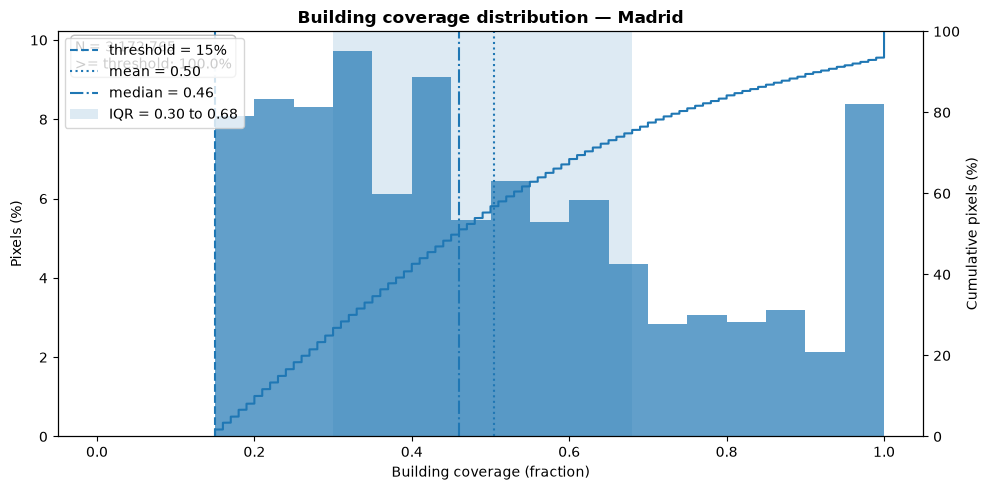

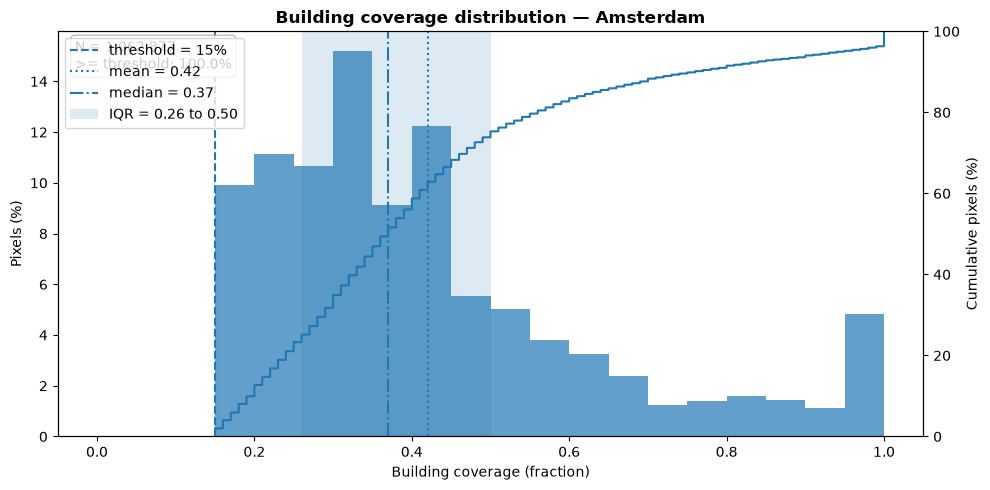

In [42]:

def plot_coverage_distribution(data, title="", coverage_col="coverage",
                                threshold=0.15, bins=20, tol=1e-9):
    x = data[coverage_col].to_numpy()
    x = x[np.isfinite(x)]
    x = np.clip(x, 0, 1)
    if len(x) == 0:
        print("No valid coverage values."); return
    n = len(x)
    mean, median = float(np.mean(x)), float(np.median(x))
    q25, q75 = np.quantile(x, [0.25, 0.75])
    edges   = np.linspace(0, 1, bins + 1)
    weights = np.ones_like(x) / n * 100

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(x, bins=edges, weights=weights, alpha=0.7, edgecolor="none")
    ax.set_xlabel("Building coverage (fraction)")
    ax.set_ylabel("Pixels (%)")
    ax.set_title(f"Building coverage distribution{' — ' + title if title else ''}",
                 fontweight="bold")
    ax.axvline(threshold, linestyle="--", label=f"threshold = {threshold:.0%}")
    ax.axvline(mean,      linestyle=":",  label=f"mean = {mean:.2f}")
    ax.axvline(median,    linestyle="-.", label=f"median = {median:.2f}")
    ax.axvspan(q25, q75,  alpha=0.15,    label=f"IQR = {q25:.2f} to {q75:.2f}")
    ax2 = ax.twinx()
    xs, cdf = np.sort(x), (np.arange(1, n+1) / n) * 100
    ax2.plot(xs, cdf, linewidth=1.5)
    ax2.set_ylabel("Cumulative pixels (%)"); ax2.set_ylim(0, 100)
    ax.text(0.02, 0.98,
            f"N = {n:,}\n>= threshold: {(x >= threshold).mean()*100:.1f}%",
            transform=ax.transAxes, va="top", ha="left",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.85, edgecolor="0.7"))
    ax.legend(loc="upper left")
    plt.tight_layout(); plt.show()

for city_name, flat, raw in CITIES:
    plot_coverage_distribution(raw, title=city_name, threshold=0.15, bins=20)

<Figure size 1000x500 with 0 Axes>

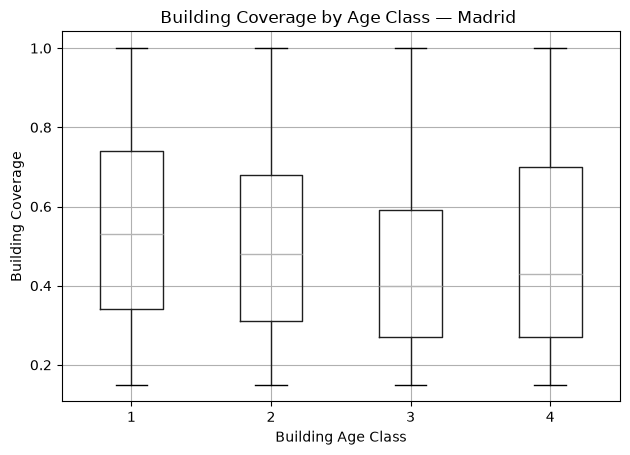

<Figure size 1000x500 with 0 Axes>

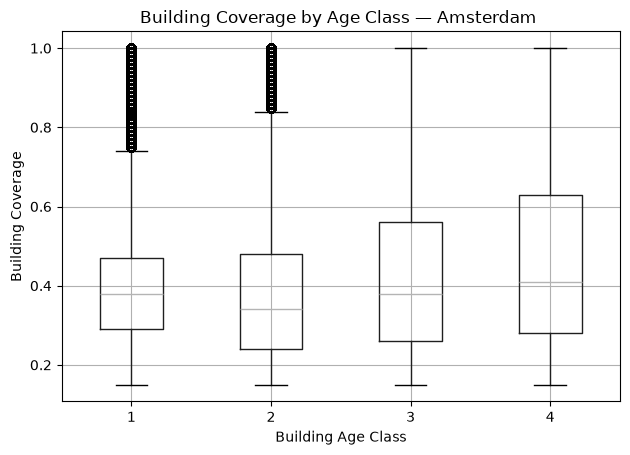

In [44]:
# ============================================
# BUILDING COVERAGE BY AGE CLASS
# ============================================

def plot_coverage_by_age_class(data, city_name):

    plt.figure(figsize=(10, 5))

    data.boxplot(
        column="coverage",
        by="age_class"
    )

    plt.title(f"Building Coverage by Age Class — {city_name}")
    plt.suptitle("")
    plt.xlabel("Building Age Class")
    plt.ylabel("Building Coverage")
    plt.tight_layout()
    plt.show()


# Madrid — Training dataset
plot_coverage_by_age_class(df, "Madrid ")

# Amsterdam — Transfer dataset
plot_coverage_by_age_class(df_ams, "Amsterdam ")

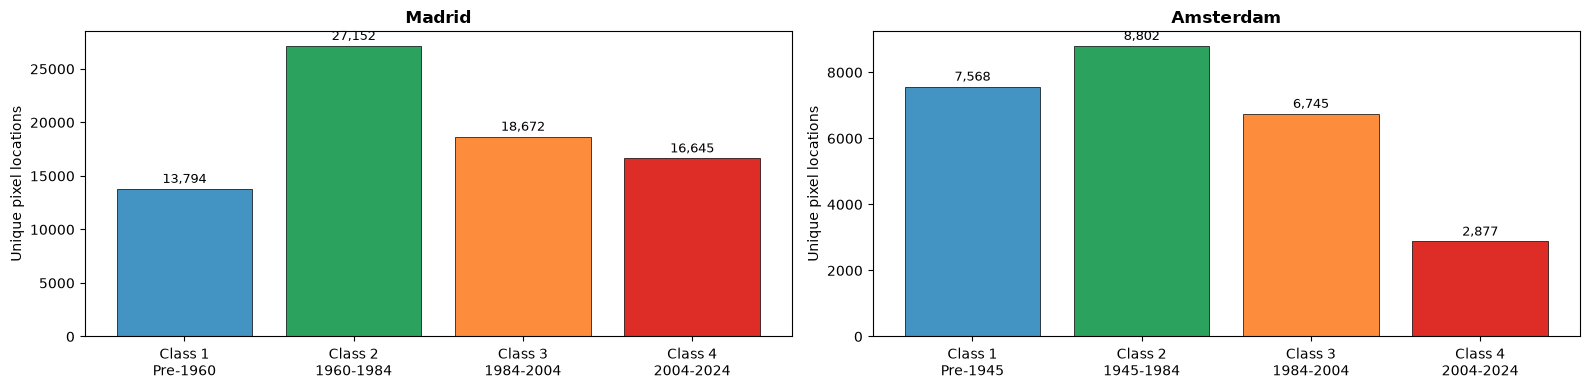

In [45]:
def plot_class_distribution(data, ax=None, title=None):
    city    = data["city"].iloc[0] if "city" in data.columns else "Madrid"
    locs    = data.drop_duplicates(subset=["px_key", "py_key"])
    counts  = locs["age_class"].value_counts().sort_index()
    labels  = CLASS_LABELS.get(city, CLASS_LABELS["Madrid"])
    colors  = [CLASS_COLORS.get(int(c), "grey") for c in counts.index]
    xlabels = ["Class " + str(int(c)) + "\n" + labels.get(int(c), "") for c in counts.index]
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 4))
    bars = ax.bar(xlabels, counts.values, color=colors, edgecolor="black", linewidth=0.5)
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, v + counts.max()*0.01,
                f"{v:,}", ha="center", va="bottom", fontsize=9)
    ax.set_ylabel("Unique pixel locations")
    if title:
        ax.set_title(title, fontweight="bold")

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, (city_name, flat, _) in zip(axes, CITIES):
    plot_class_distribution(flat, ax=ax, title=city_name)
plt.tight_layout(); plt.show()

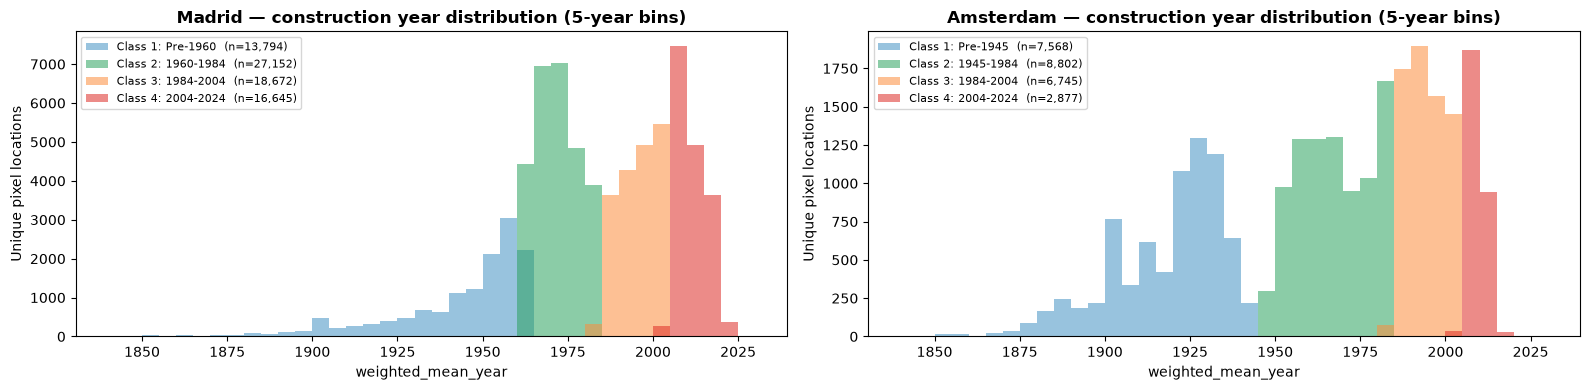

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=False)
bins = np.arange(1840, 2031, 5)

for ax, (city_name, flat, _) in zip(axes, CITIES):
    df_locs = flat.drop_duplicates(subset=['px_key', 'py_key'])
    labels  = CLASS_LABELS.get(city_name, CLASS_LABELS['Madrid'])
    for cls in [1, 2, 3, 4]:
        subset = df_locs[df_locs['age_class'] == cls]['weighted_mean_year']
        if subset.empty: continue
        lbl = labels.get(cls, f'Class {cls}')
        ax.hist(subset, bins=bins, alpha=0.55, color=CLASS_COLORS[cls],
                label=f'Class {cls}: {lbl}  (n={len(subset):,})')
    ax.set_xlabel('weighted_mean_year')
    ax.set_ylabel('Unique pixel locations')
    ax.set_title(f'{city_name} — construction year distribution (5-year bins)',
                 fontweight='bold')
    ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

In [47]:
def find_best_pixels(data, age_class, n=3):
    """
    Select n pixels for a class with:
      - different construction years (one from each year-tertile of the class)
      - spatial spread (each successive pick maximises min distance to prior picks)
    """
    cls_df = data[(data['age_class'] == int(age_class)) &
                  data['Blue'].notna() &
                  data['weighted_mean_year'].notna()]
    if cls_df.empty:
        return []

    # One row per pixel: observation count + construction year
    pix = (cls_df.groupby(['px_key', 'py_key'])
                 .agg(obs=('Blue', 'count'), yr=('weighted_mean_year', 'first'))
                 .reset_index()
                 .sort_values('yr')
                 .reset_index(drop=True))

    if len(pix) <= n:
        return list(zip(pix['px_key'].astype(int), pix['py_key'].astype(int)))

    # Split into n equal year-tertiles
    size   = len(pix) // n
    groups = [pix.iloc[i * size : len(pix) if i == n - 1 else (i + 1) * size]
              for i in range(n)]

    # Greedy: from each tertile pick the pixel that maximises min distance
    # to already-selected pixels (first pick: most observations)
    selected = []
    for grp in groups:
        if not selected:
            row = grp.nlargest(1, 'obs').iloc[0]
        else:
            coords  = grp[['px_key', 'py_key']].values.astype(float)
            sel_arr = np.array(selected, dtype=float)
            min_d   = np.sqrt(((coords[:, None, :] - sel_arr[None, :, :]) ** 2)
                              .sum(axis=2)).min(axis=1)
            row = grp.iloc[min_d.argmax()]
        selected.append((int(row['px_key']), int(row['py_key'])))

    return selected

def get_pixel_ts(data, px, py, band):
    pix = data[(data['px_key'] == px) & (data['py_key'] == py)].sort_values('year')
    return pix[['year', band, 'age_class']].dropna(subset=[band]).reset_index(drop=True)

class_pixels = {}
for city_name, flat, _ in CITIES:
    class_pixels[city_name] = {}
    for cls in [1, 2, 3, 4]:
        px_list = find_best_pixels(flat, cls, n=3)
        class_pixels[city_name][cls] = px_list
        lbl = CLASS_LABELS.get(city_name, CLASS_LABELS['Madrid']).get(cls, '')
        yrs = [int(round(flat[(flat['px_key'] == px) & (flat['py_key'] == py)]
                         ['weighted_mean_year'].iloc[0]))
               for px, py in px_list]
        dists = []
        for j in range(1, len(px_list)):
            dx = px_list[j][0] - px_list[0][0]
            dy = px_list[j][1] - px_list[0][1]
            dists.append(int(((dx**2 + dy**2) ** 0.5) * 30))  # metres from first pixel
        print(f"{city_name:12s}  Class {cls} ({lbl:12s}): "
              f"years {yrs},  sep >{min(dists) if dists else 0} m")

Madrid        Class 1 (Pre-1960    ): years [1850, 1950, 1960],  sep >15651 m
Madrid        Class 2 (1960-1984   ): years [1960, 1972, 1980],  sep >14696 m
Madrid        Class 3 (1984-2004   ): years [1984, 1998, 2004],  sep >14974 m
Madrid        Class 4 (2004-2024   ): years [2004, 2011, 2014],  sep >18678 m
Amsterdam     Class 1 (Pre-1945    ): years [1850, 1914, 1931],  sep >10442 m
Amsterdam     Class 2 (1945-1984   ): years [1945, 1969, 1975],  sep >9631 m
Amsterdam     Class 3 (1984-2004   ): years [1984, 1993, 1999],  sep >14212 m
Amsterdam     Class 4 (2004-2024   ): years [2004, 2009, 2013],  sep >10103 m


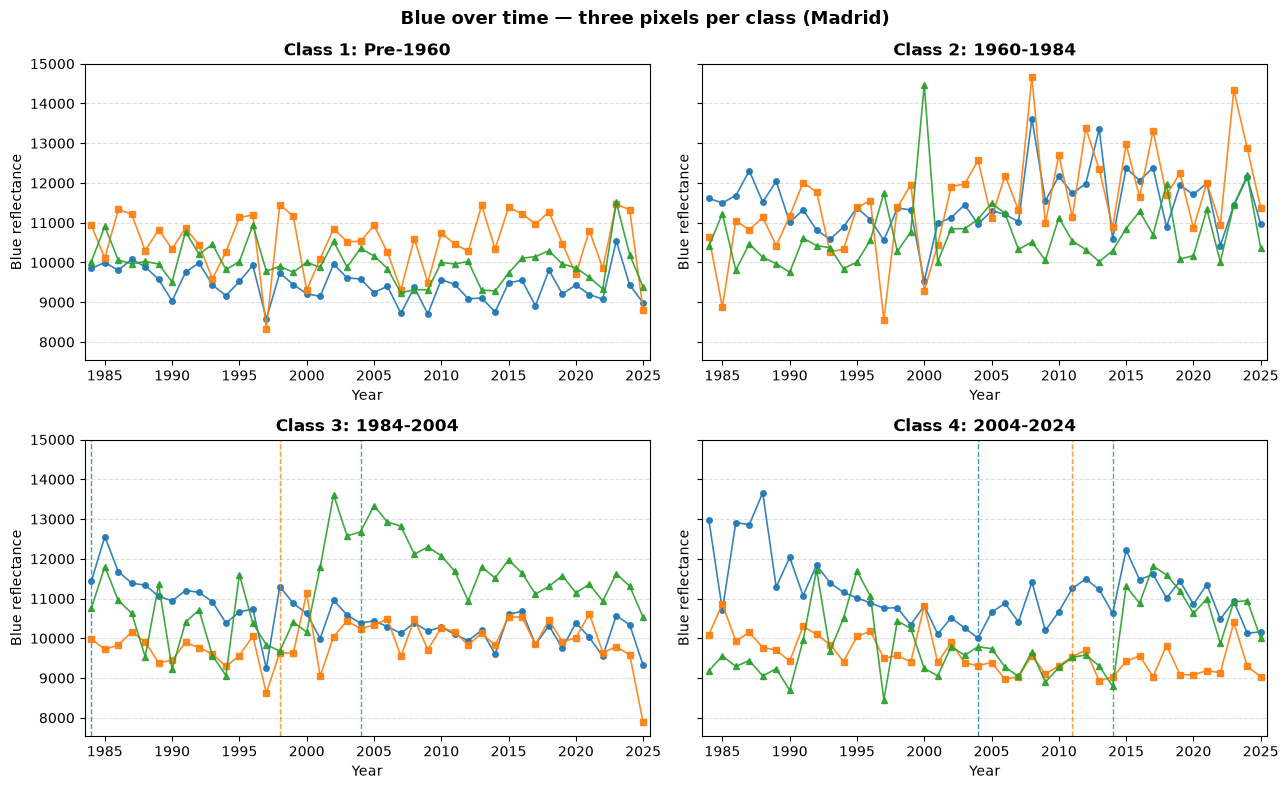

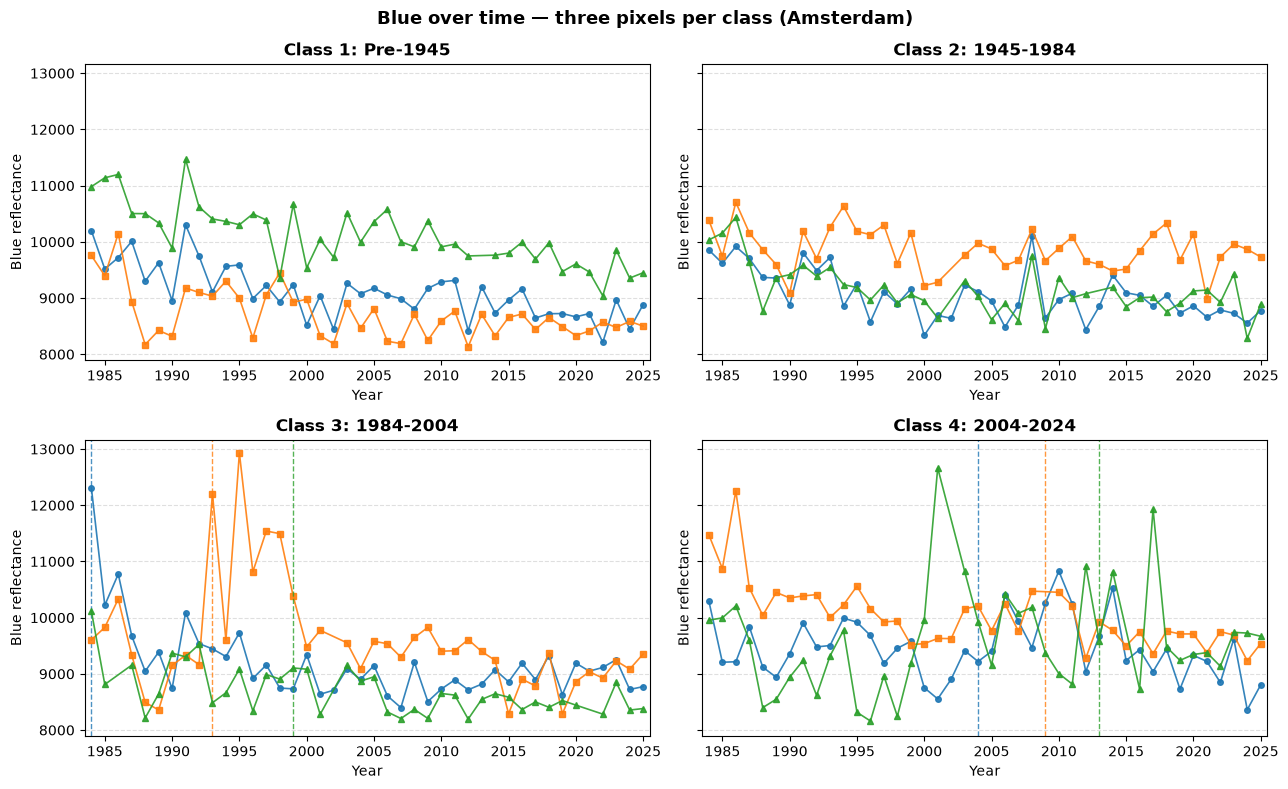

In [51]:
MARKERS      = ["o", "s", "^"]
PIXEL_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c"]  # same three colors across all class subplots

def plot_pixel_ts(band, data, pixels):
    city   = data["city"].iloc[0]
    labels = CLASS_LABELS.get(city, CLASS_LABELS["Madrid"])
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
    for ax, cls in zip(axes.flat, [1, 2, 3, 4]):
        px_list = pixels[cls]
        if not px_list:
            ax.set_visible(False); continue
        for i, (px, py) in enumerate(px_list):
            color = PIXEL_COLORS[i]
            ts    = get_pixel_ts(data, px, py, band)
            ax.plot(ts["year"], ts[band], marker=MARKERS[i], markersize=4,
                    color=color, linewidth=1.2, alpha=0.9)
            if cls in [3, 4]:
                yr_rows = data[(data["px_key"] == px) & (data["py_key"] == py)]["weighted_mean_year"]
                if not yr_rows.empty:
                    yr = int(round(yr_rows.iloc[0]))
                    ax.axvline(yr, color=color, linestyle="--", linewidth=1.0, alpha=0.8)
        ax.set_xlim(YEAR_MIN - 0.5, YEAR_MAX + 0.5)
        ax.set_title(f"Class {cls}: {labels.get(cls, '')}", fontweight="bold")
        ax.set_xlabel("Year"); ax.set_ylabel(f"{band} reflectance")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
    plt.suptitle(f"{band} over time — three pixels per class ({city})",
                 fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

for city_name, flat, _ in CITIES:
    plot_pixel_ts("Blue", flat, class_pixels[city_name])

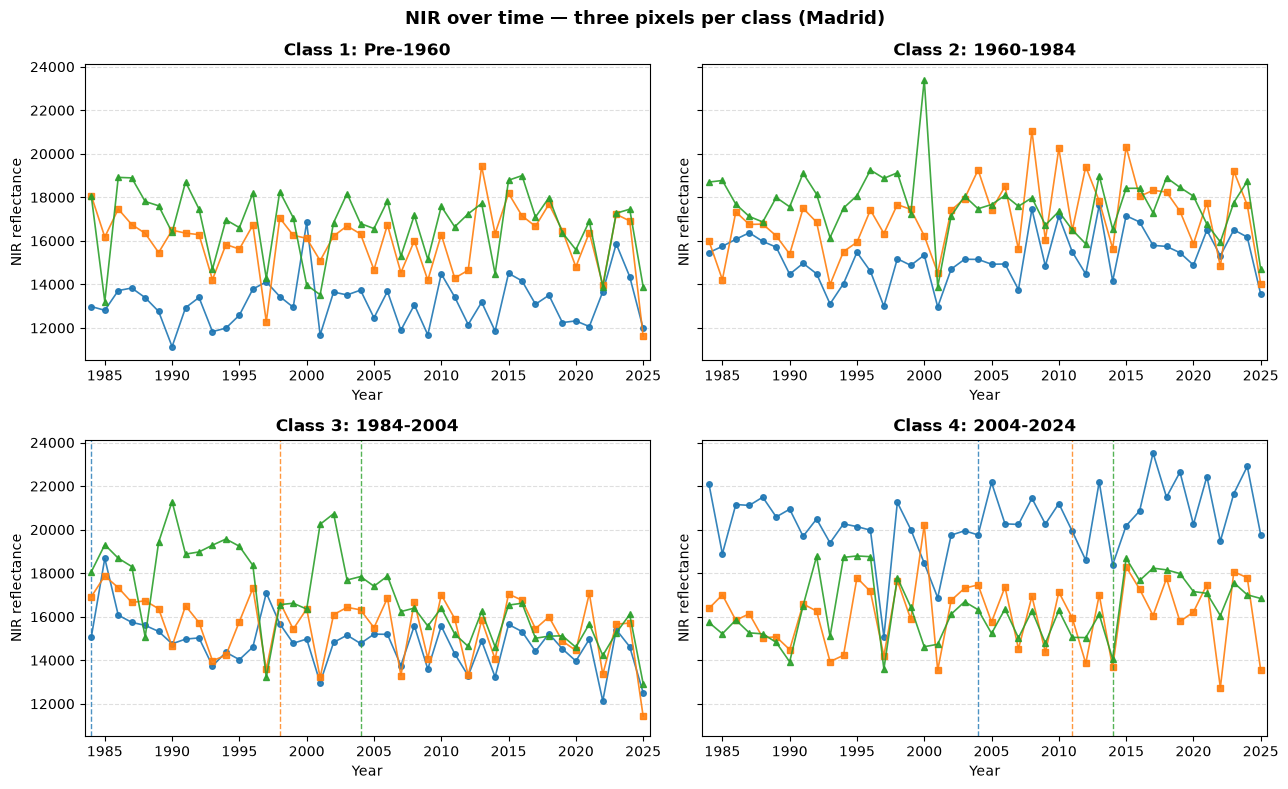

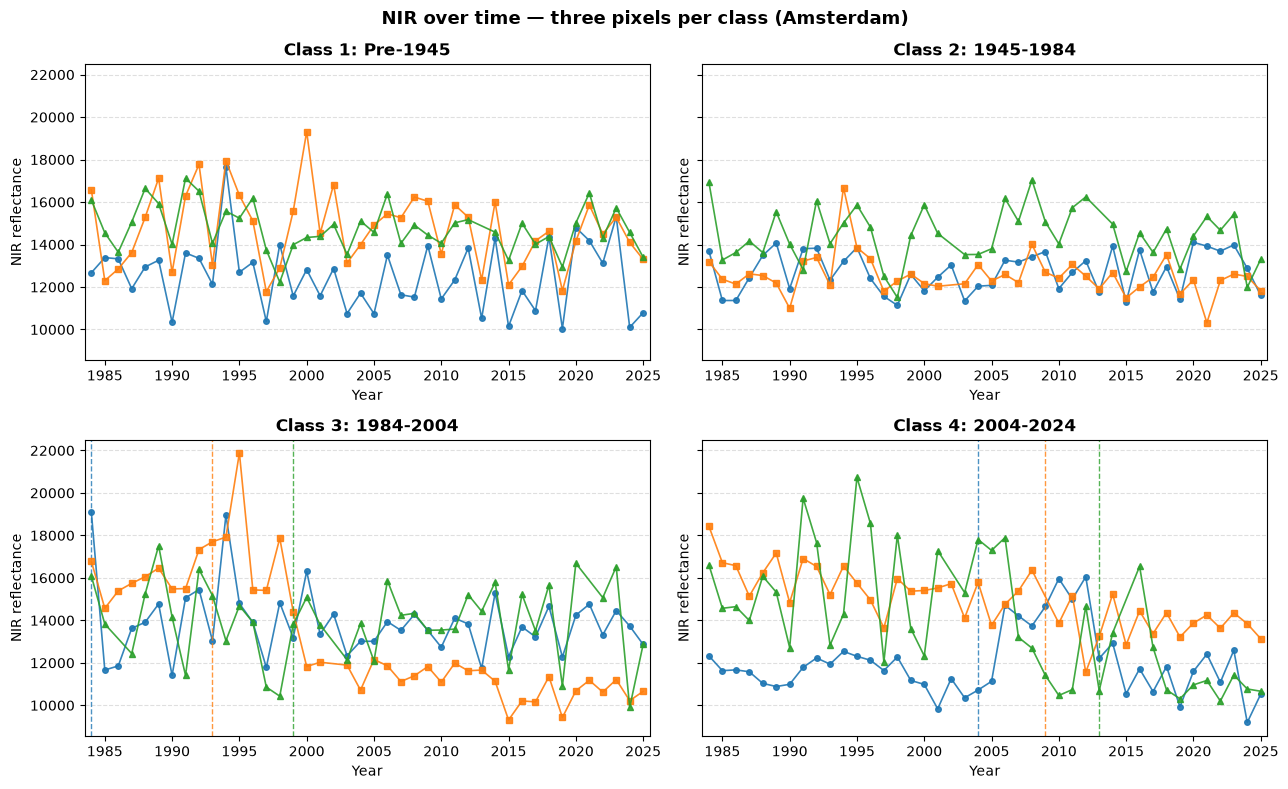

In [52]:
for city_name, flat, _ in CITIES:
    plot_pixel_ts('NIR', flat, class_pixels[city_name])

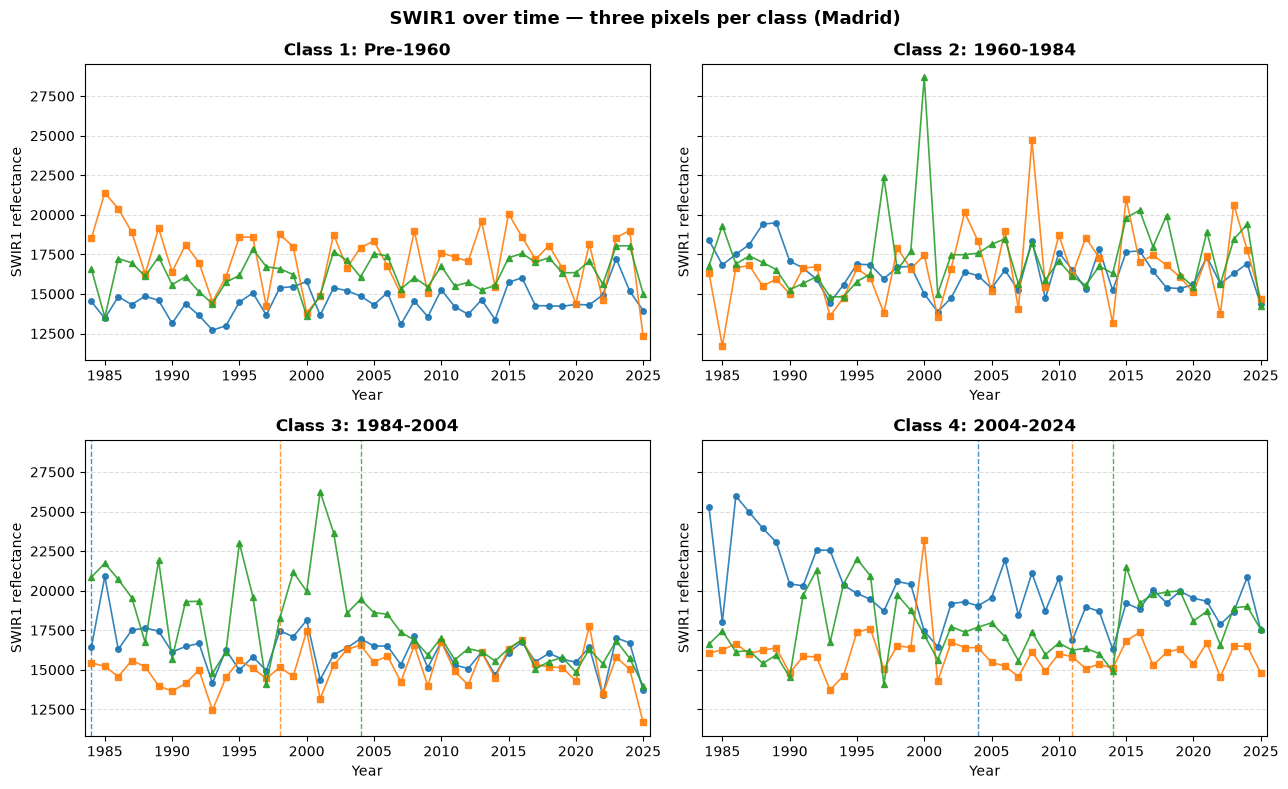

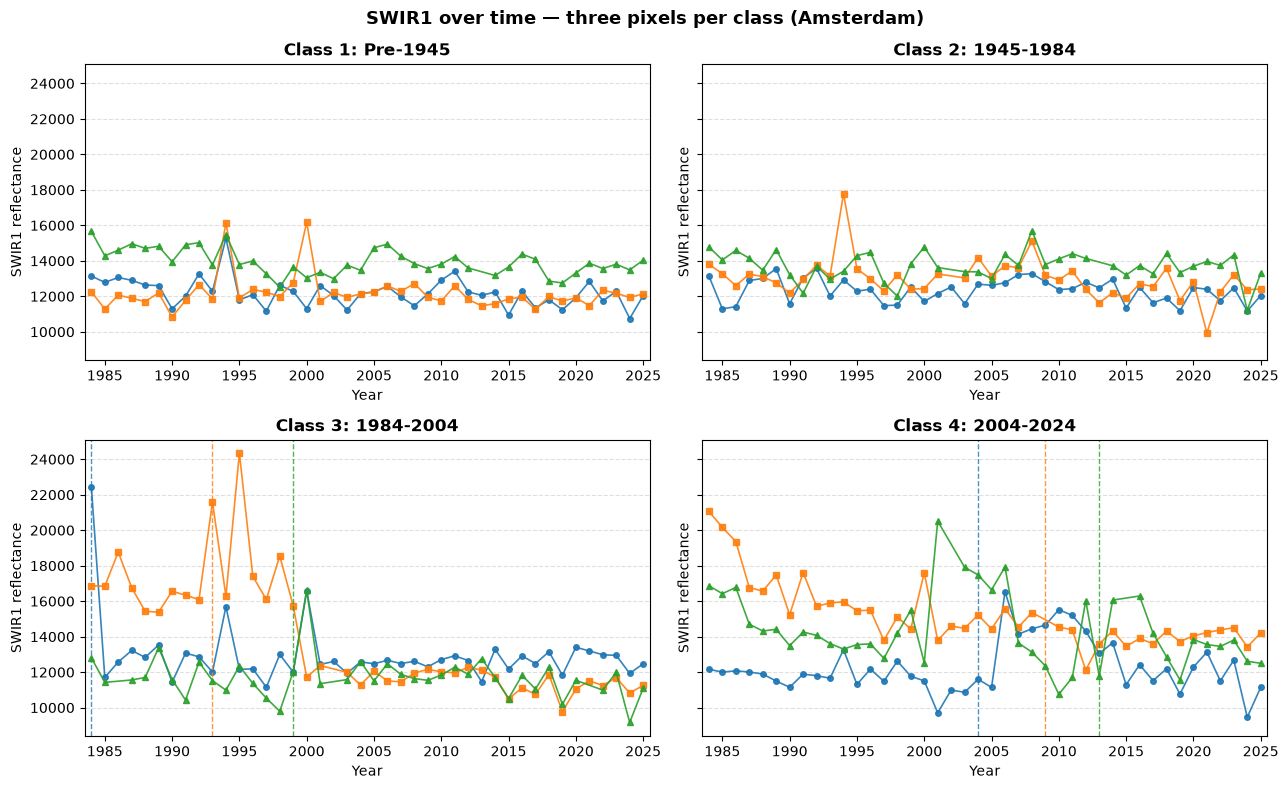

In [53]:
for city_name, flat, _ in CITIES:
    plot_pixel_ts('SWIR1', flat, class_pixels[city_name])

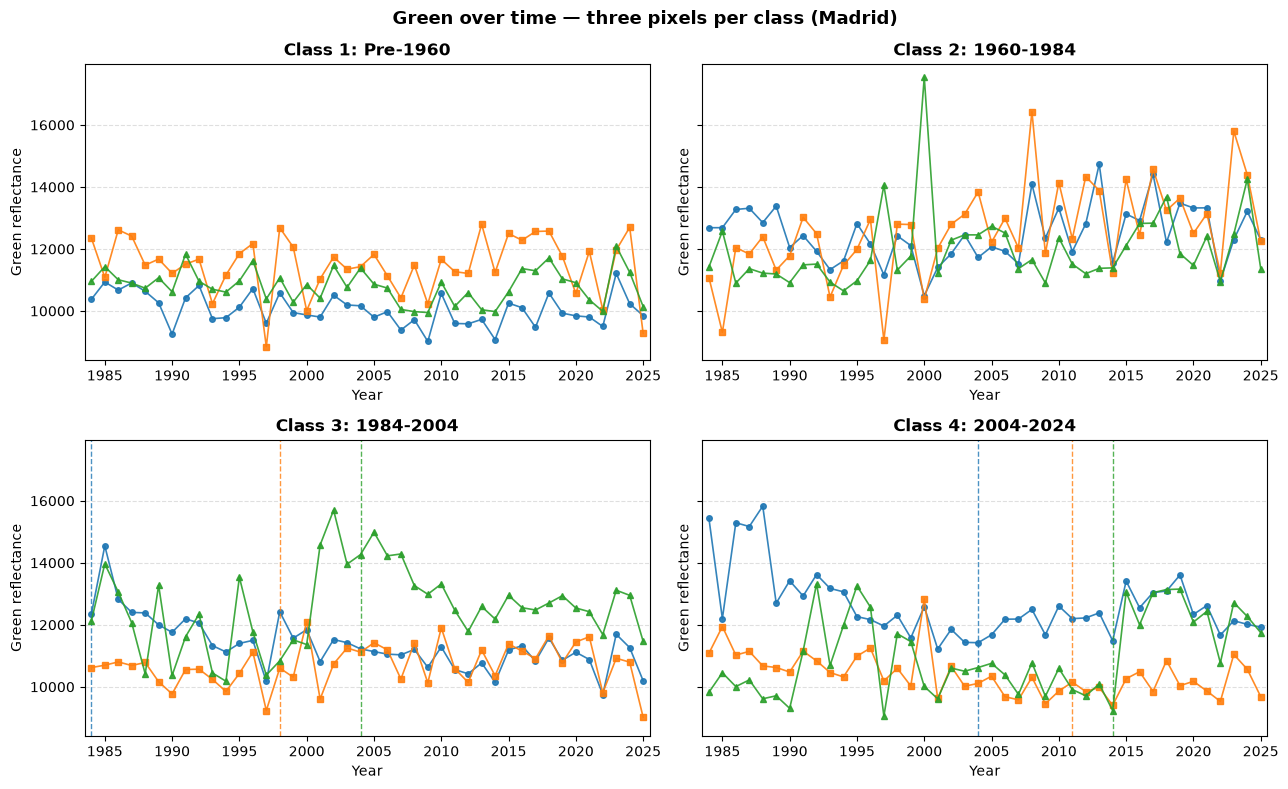

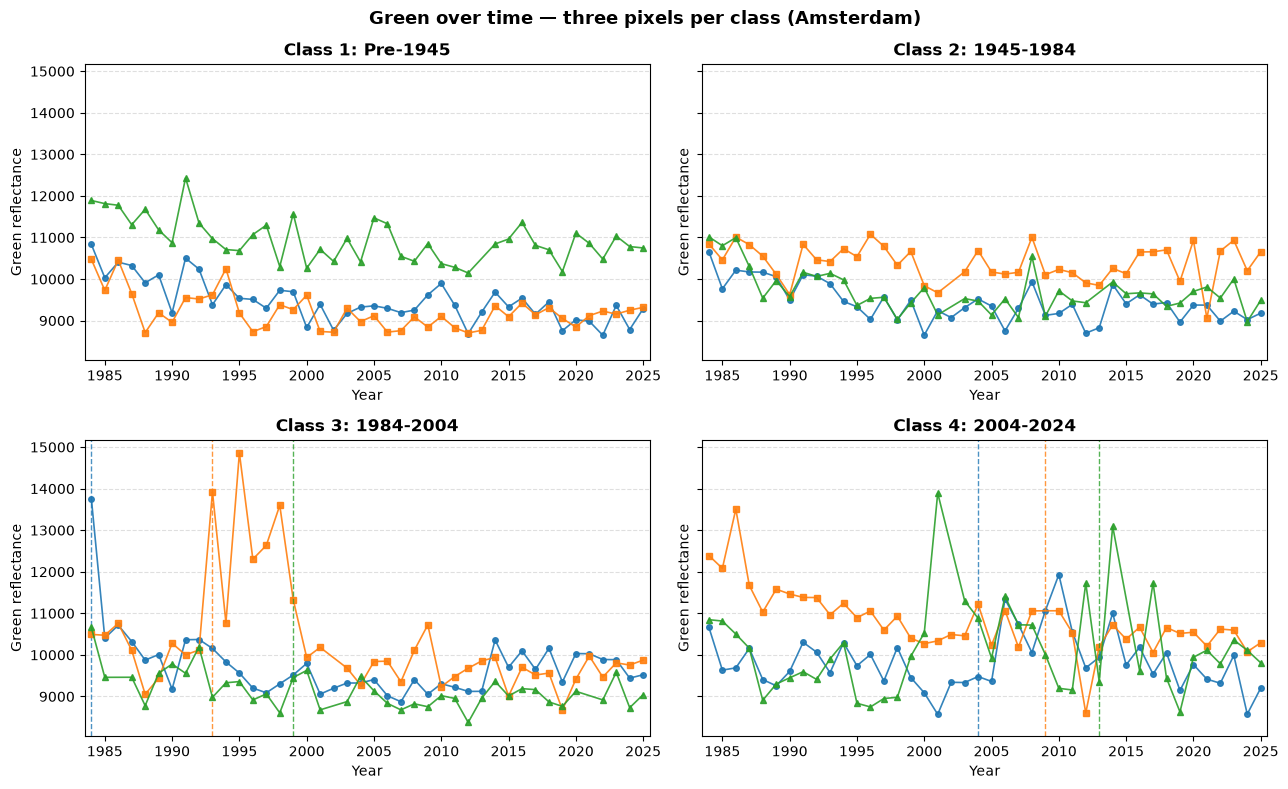

In [54]:
for city_name, flat, _ in CITIES:
    plot_pixel_ts('Green', flat, class_pixels[city_name])

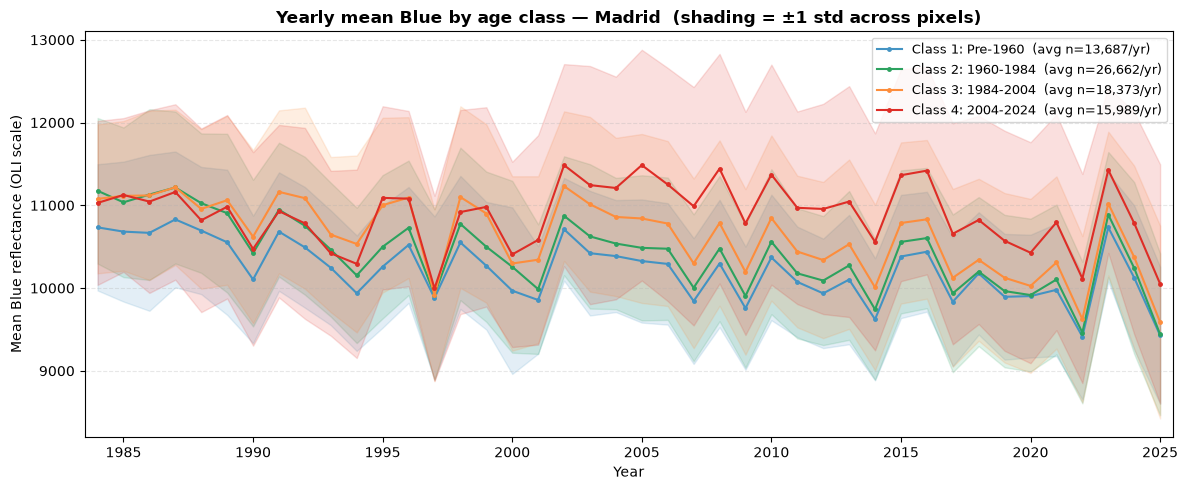

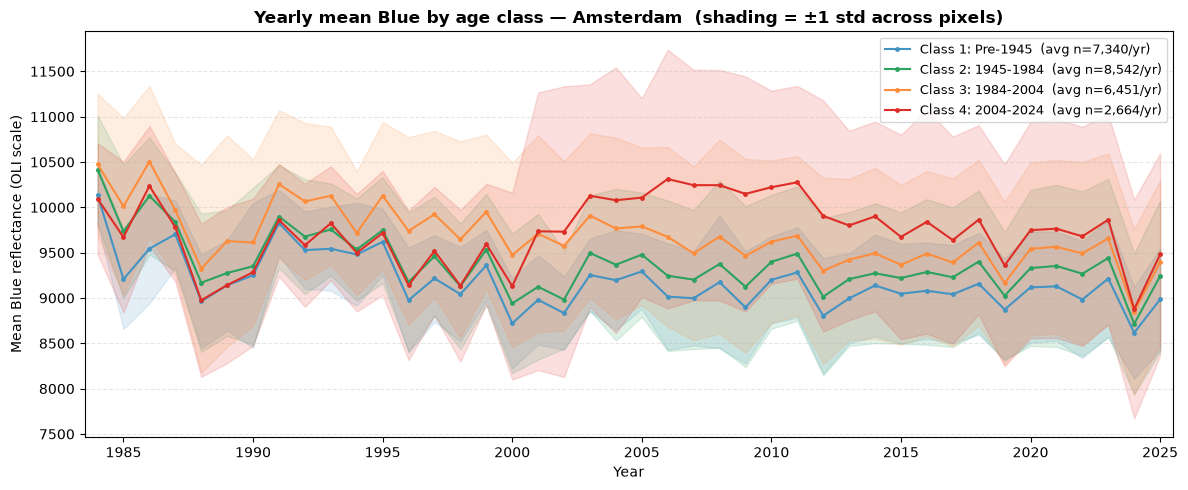

In [55]:
def get_yearly_means(data, band):
    tmp = data[['year', 'age_class', band]].dropna()
    return tmp.groupby(['year', 'age_class'])[band].agg(['mean', 'std', 'count']).reset_index()

def plot_yearly_class_means(band, data):
    city   = data['city'].iloc[0]
    labels = CLASS_LABELS.get(city, CLASS_LABELS['Madrid'])
    stats  = get_yearly_means(data, band)
    fig, ax = plt.subplots(figsize=(12, 5))
    for cls in sorted(stats['age_class'].dropna().unique()):
        cls   = int(cls)
        sub   = stats[stats['age_class'] == cls].sort_values('year')
        color = CLASS_COLORS.get(cls, 'grey')
        lbl   = labels.get(cls, f'Class {cls}')
        avg_n = int(sub['count'].mean())
        ax.plot(sub['year'], sub['mean'], color=color, marker='.', markersize=5,
                linewidth=1.5, label=f'Class {cls}: {lbl}  (avg n={avg_n:,}/yr)')
        ax.fill_between(sub['year'],
                        sub['mean'] - sub['std'], sub['mean'] + sub['std'],
                        color=color, alpha=0.15)
    ax.set_xlim(YEAR_MIN - 0.5, YEAR_MAX + 0.5)
    ax.set_xlabel('Year')
    ax.set_ylabel(f'Mean {band} reflectance (OLI scale)')
    ax.set_title(f'Yearly mean {band} by age class — {city}  (shading = ±1 std across pixels)',
                 fontweight='bold')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout(); plt.show()

for city_name, flat, _ in CITIES:
    plot_yearly_class_means('Blue', flat)

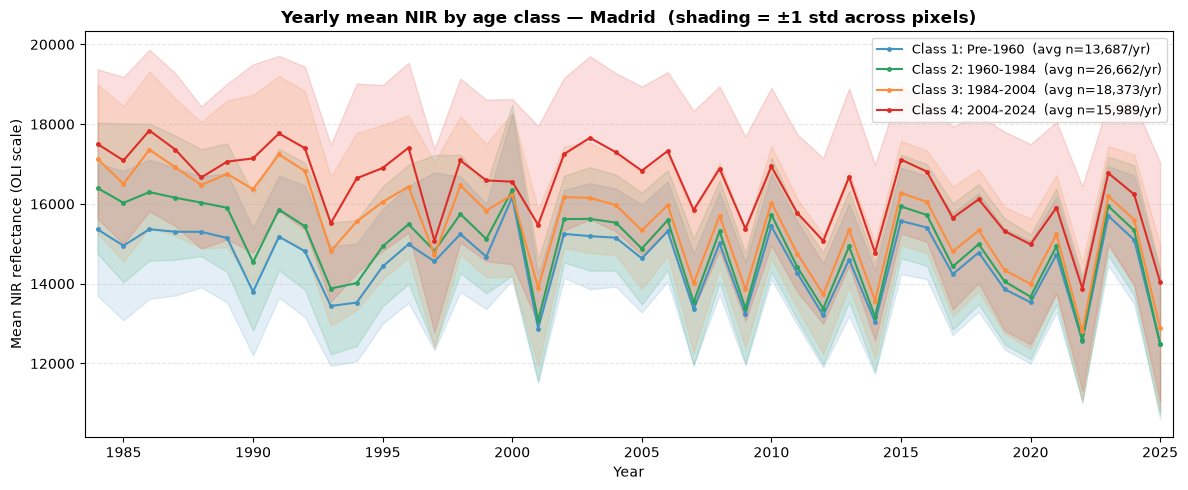

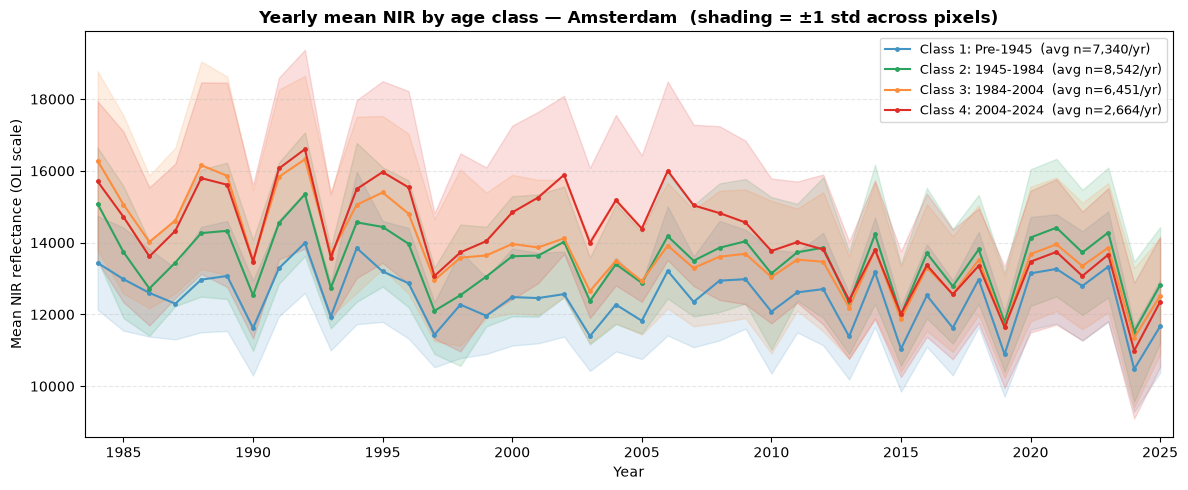

In [56]:
for city_name, flat, _ in CITIES:
    plot_yearly_class_means('NIR', flat)

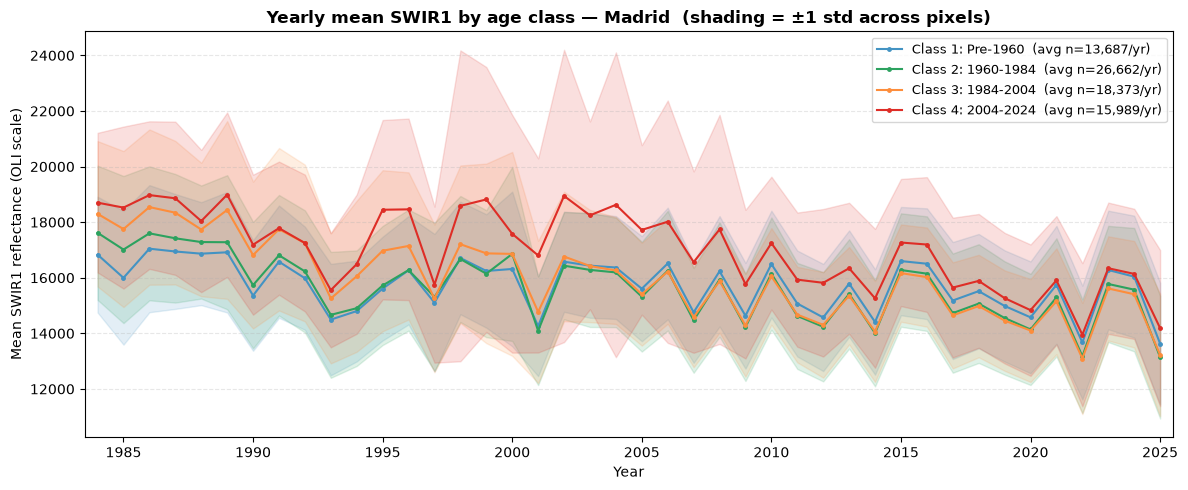

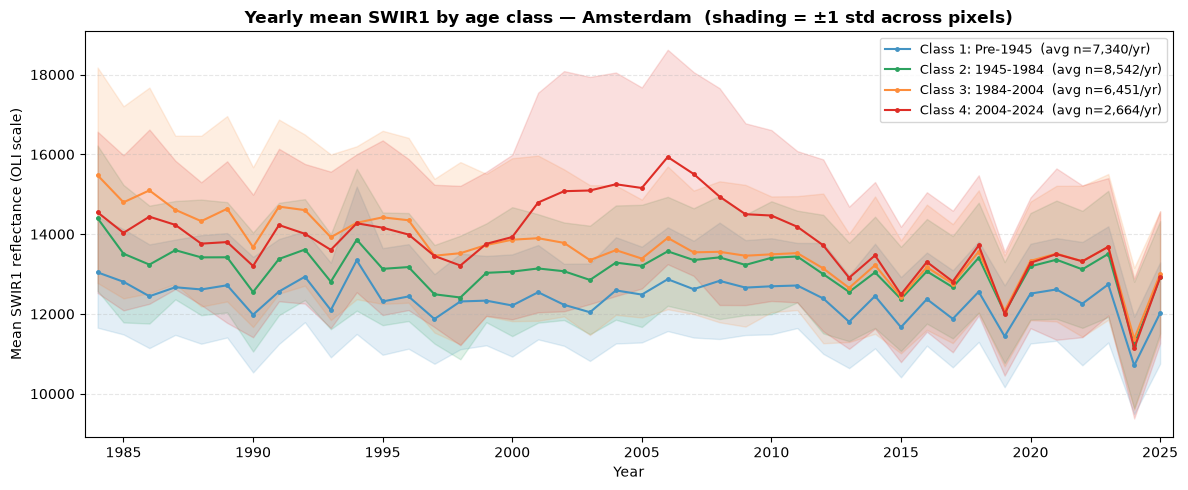

In [57]:
for city_name, flat, _ in CITIES:
    plot_yearly_class_means('SWIR1', flat)

In [58]:
def compute_pixel_stats(flat):
    """Per-pixel temporal mean/std and year-on-year diff mean/std for all bands."""
    s = flat[flat['age_class'].notna()].copy()
    s = s.sort_values(['px_key', 'py_key', 'year'])

    grp  = s.groupby(['px_key', 'py_key', 'age_class'])[BASE_BANDS]
    base = pd.concat([grp.mean().add_suffix('_mean'),
                      grp.std().add_suffix('_std')], axis=1).reset_index()
    base['age_class'] = base['age_class'].astype(int)

    for b in BASE_BANDS:
        s[f'd_{b}'] = s.groupby(['px_key', 'py_key'])[b].diff()
    dcols    = [f'd_{b}' for b in BASE_BANDS]
    dgrp     = s.groupby(['px_key', 'py_key'])[dcols]
    diff_base = pd.concat([dgrp.mean().add_suffix('_mean'),
                           dgrp.std().add_suffix('_std')], axis=1).reset_index()

    return base.merge(diff_base, on=['px_key', 'py_key'])

pixel_stats = {}
for city_name, flat, _ in CITIES:
    pixel_stats[city_name] = compute_pixel_stats(flat)
    print(f"{city_name}: {len(pixel_stats[city_name]):,} pixels")

Madrid: 76,263 pixels
Amsterdam: 25,992 pixels


In [59]:
def plot_dodged_hist(ax, ps, col, n_bins=40):
    classes = sorted(ps['age_class'].dropna().unique().astype(int))
    all_v   = ps[col].dropna().values
    if len(all_v) == 0:
        return
    lo, hi  = np.percentile(all_v, [1, 99])
    bins    = np.linspace(lo, hi, n_bins + 1)
    bw      = bins[1] - bins[0]
    bar_w   = bw / len(classes) * 0.88
    for i, cls in enumerate(classes):
        vals = ps.loc[ps['age_class'] == cls, col].dropna().values
        counts, _ = np.histogram(vals, bins=bins)
        counts = counts / max(counts.sum(), 1)
        offset = (i - (len(classes) - 1) / 2) * bar_w
        ax.bar(bins[:-1] + bw / 2 + offset, counts, width=bar_w,
               color=CLASS_COLORS.get(cls, 'grey'), alpha=0.85,
               label=f'Class {cls}')
    ax.tick_params(labelsize=7)

def plot_metric_grid(col_fmt, suptitle, xlabel):
    fig, axes = plt.subplots(2, len(BASE_BANDS), figsize=(20, 7), sharey='row')
    for row, (city_name, flat, _) in enumerate(CITIES):
        ps = pixel_stats[city_name]
        for ci, band in enumerate(BASE_BANDS):
            ax = axes[row, ci]
            plot_dodged_hist(ax, ps, col_fmt.format(band=band))
            if row == 0:
                ax.set_title(band, fontweight='bold', fontsize=10)
            if ci == 0:
                ax.set_ylabel(f'{city_name}\nFraction', fontsize=9)
            if row == 1:
                ax.set_xlabel(xlabel, fontsize=8)
    handles, lbls = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, lbls, loc='lower center', ncol=4, fontsize=9,
               bbox_to_anchor=(0.5, -0.01))
    fig.suptitle(suptitle, fontsize=13, fontweight='bold')
    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

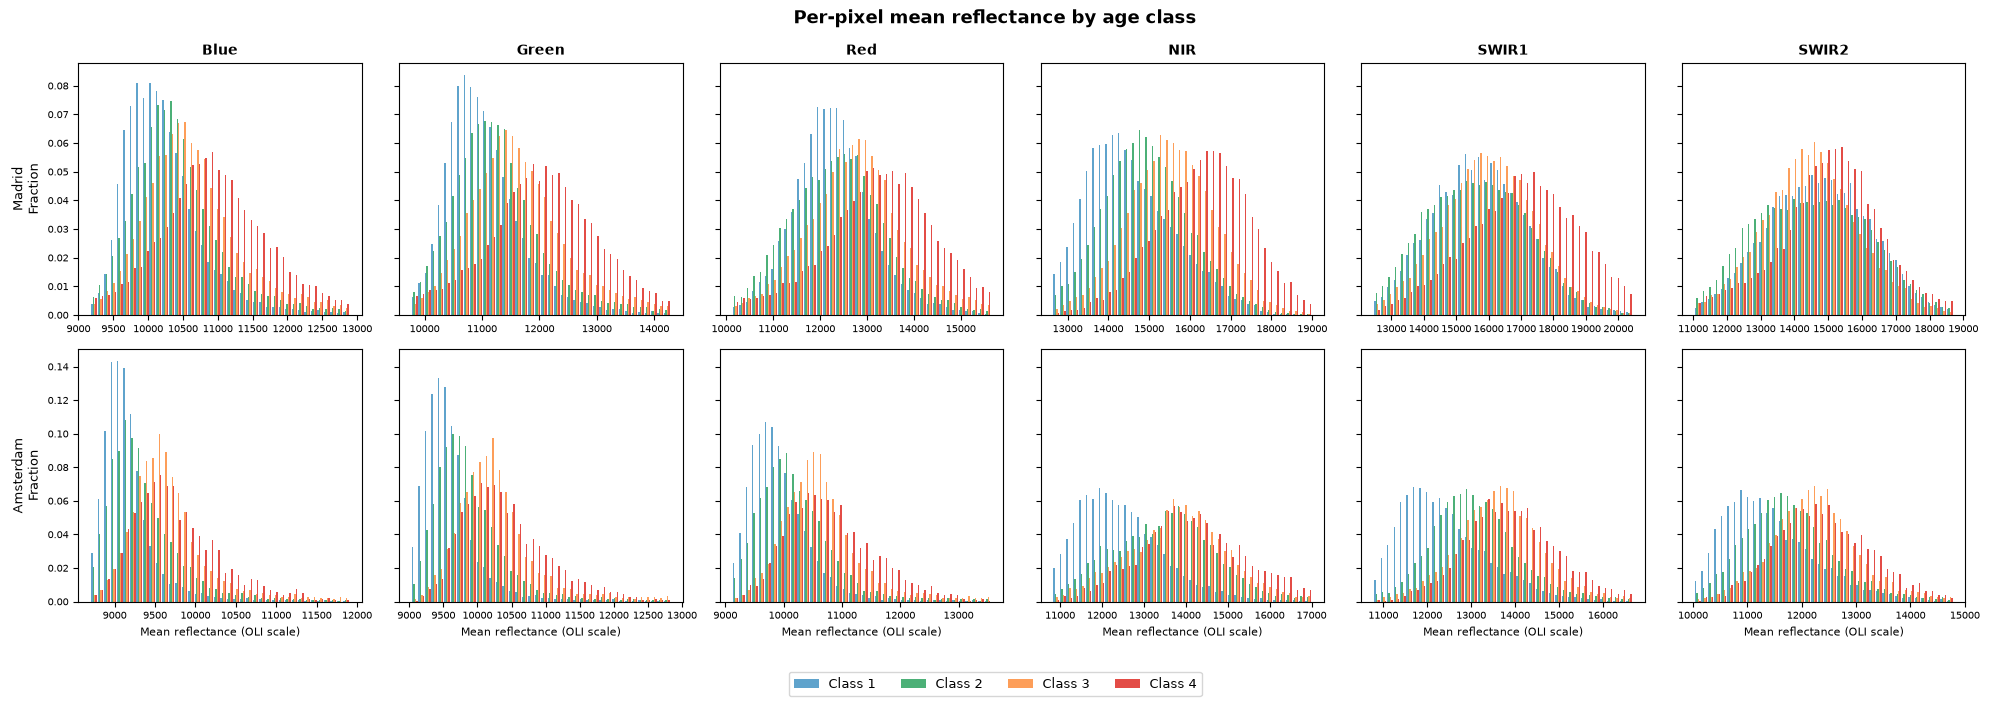

In [60]:
plot_metric_grid('{band}_mean',
                 'Per-pixel mean reflectance by age class',
                 'Mean reflectance (OLI scale)')

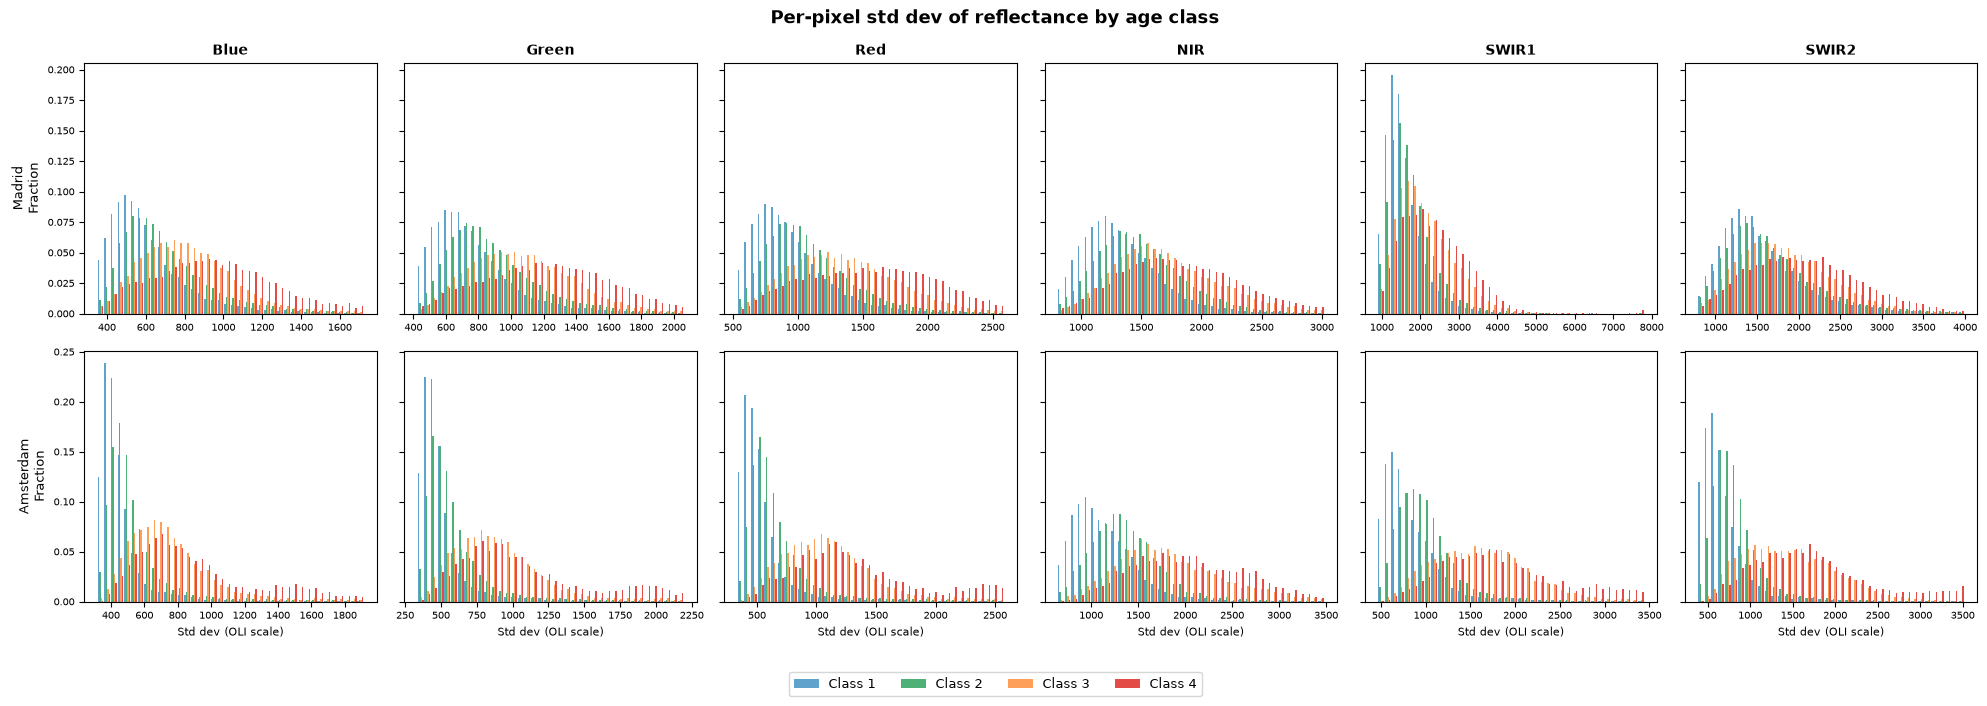

In [61]:
plot_metric_grid('{band}_std',
                 'Per-pixel std dev of reflectance by age class',
                 'Std dev (OLI scale)')

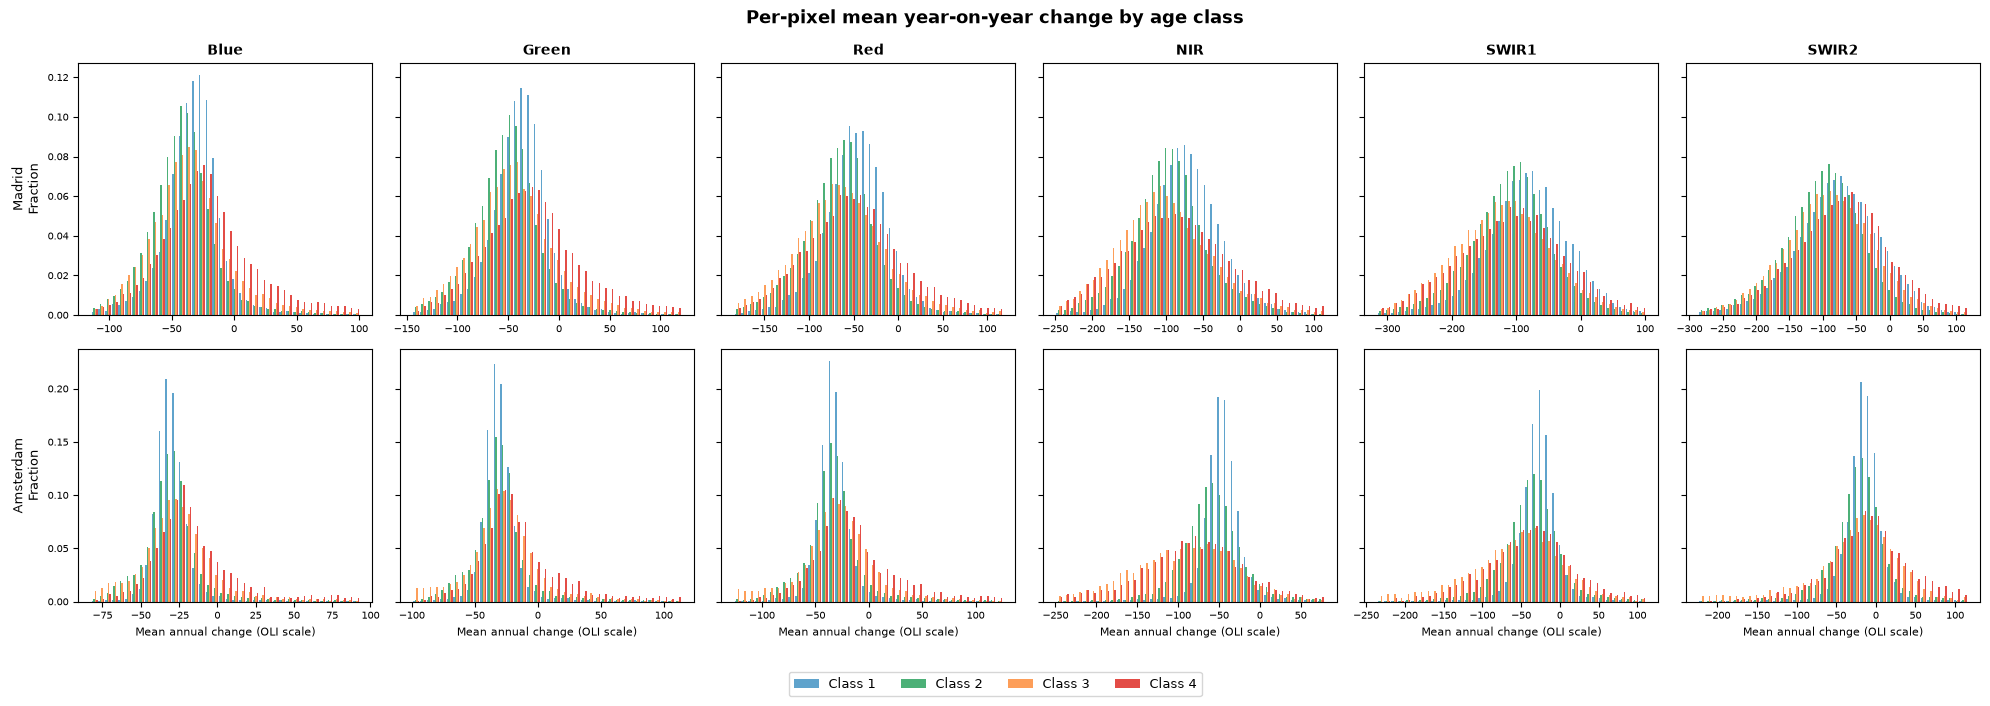

In [62]:
plot_metric_grid('d_{band}_mean',
                 'Per-pixel mean year-on-year change by age class',
                 'Mean annual change (OLI scale)')

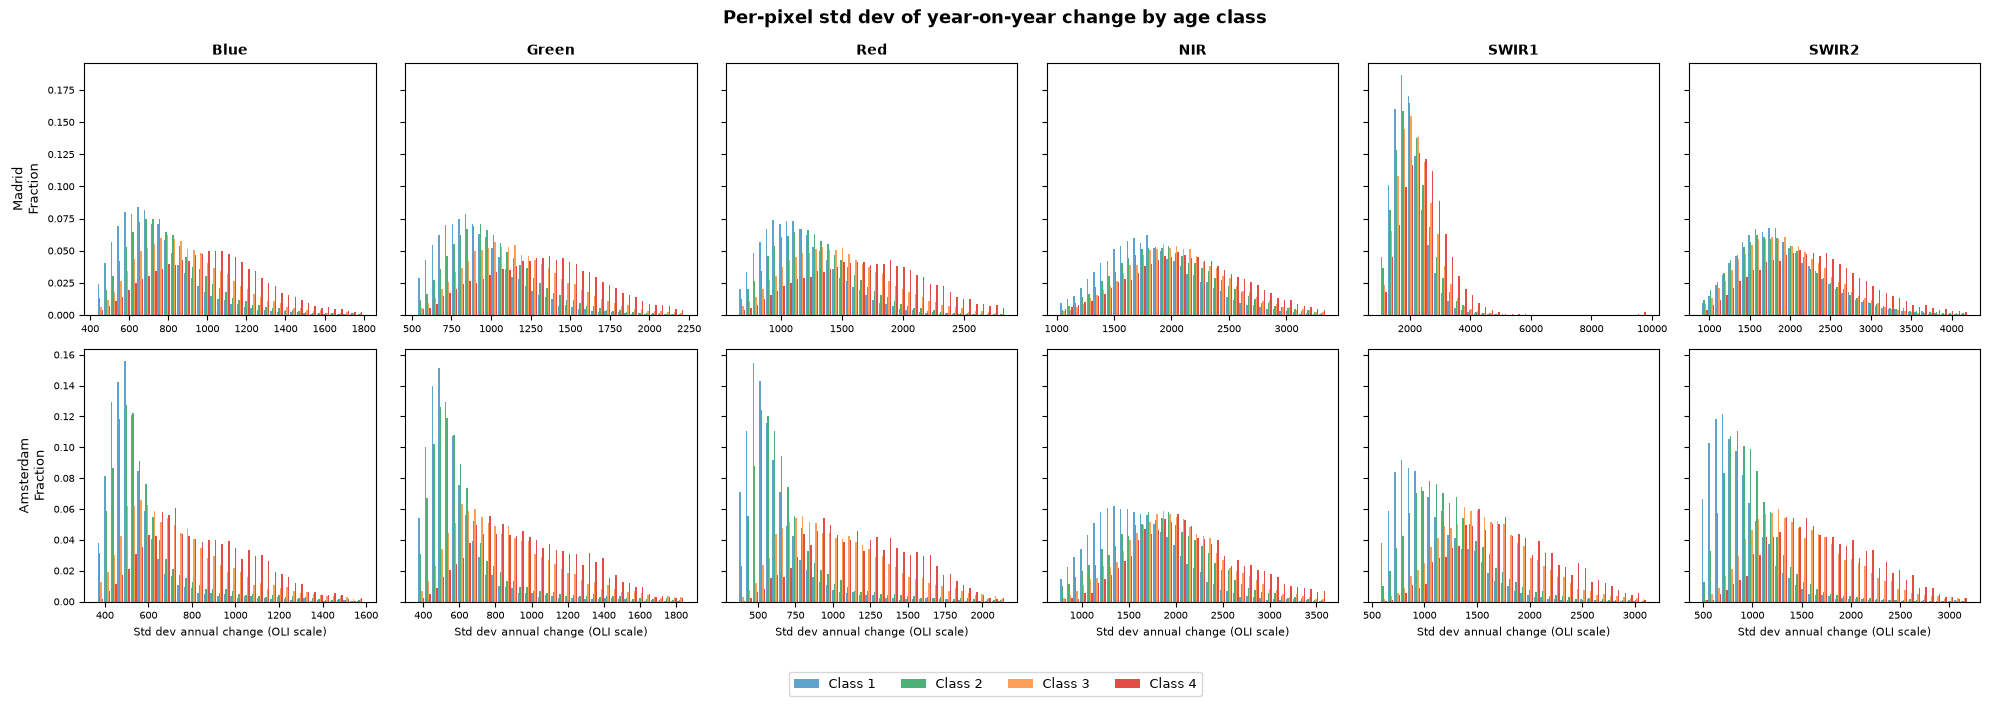

In [63]:
plot_metric_grid('d_{band}_std',
                 'Per-pixel std dev of year-on-year change by age class',
                 'Std dev annual change (OLI scale)')

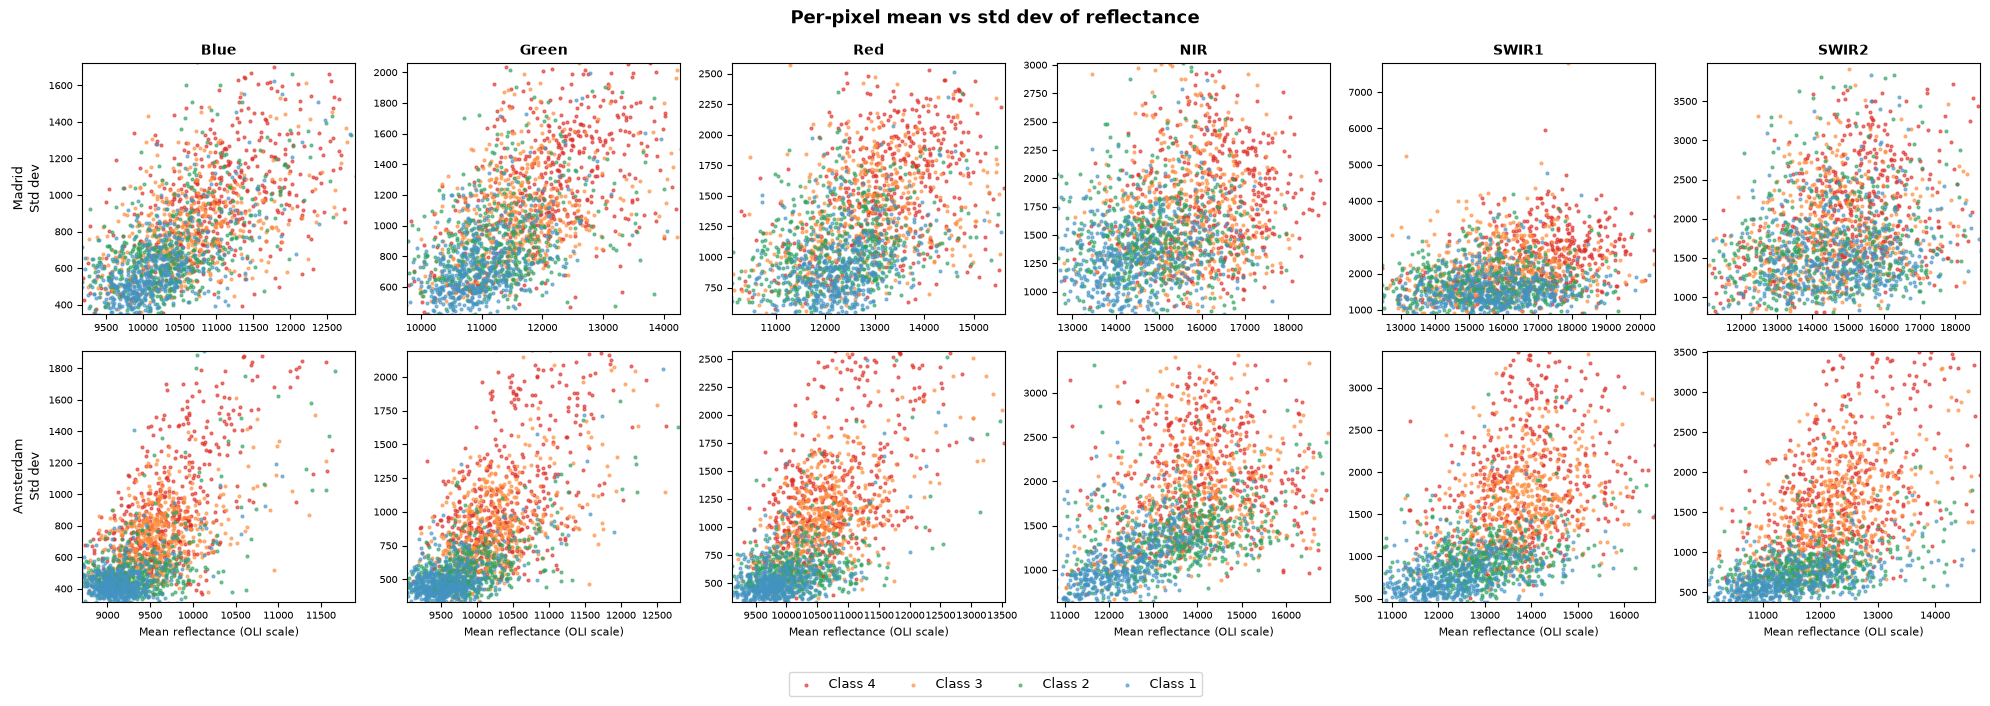

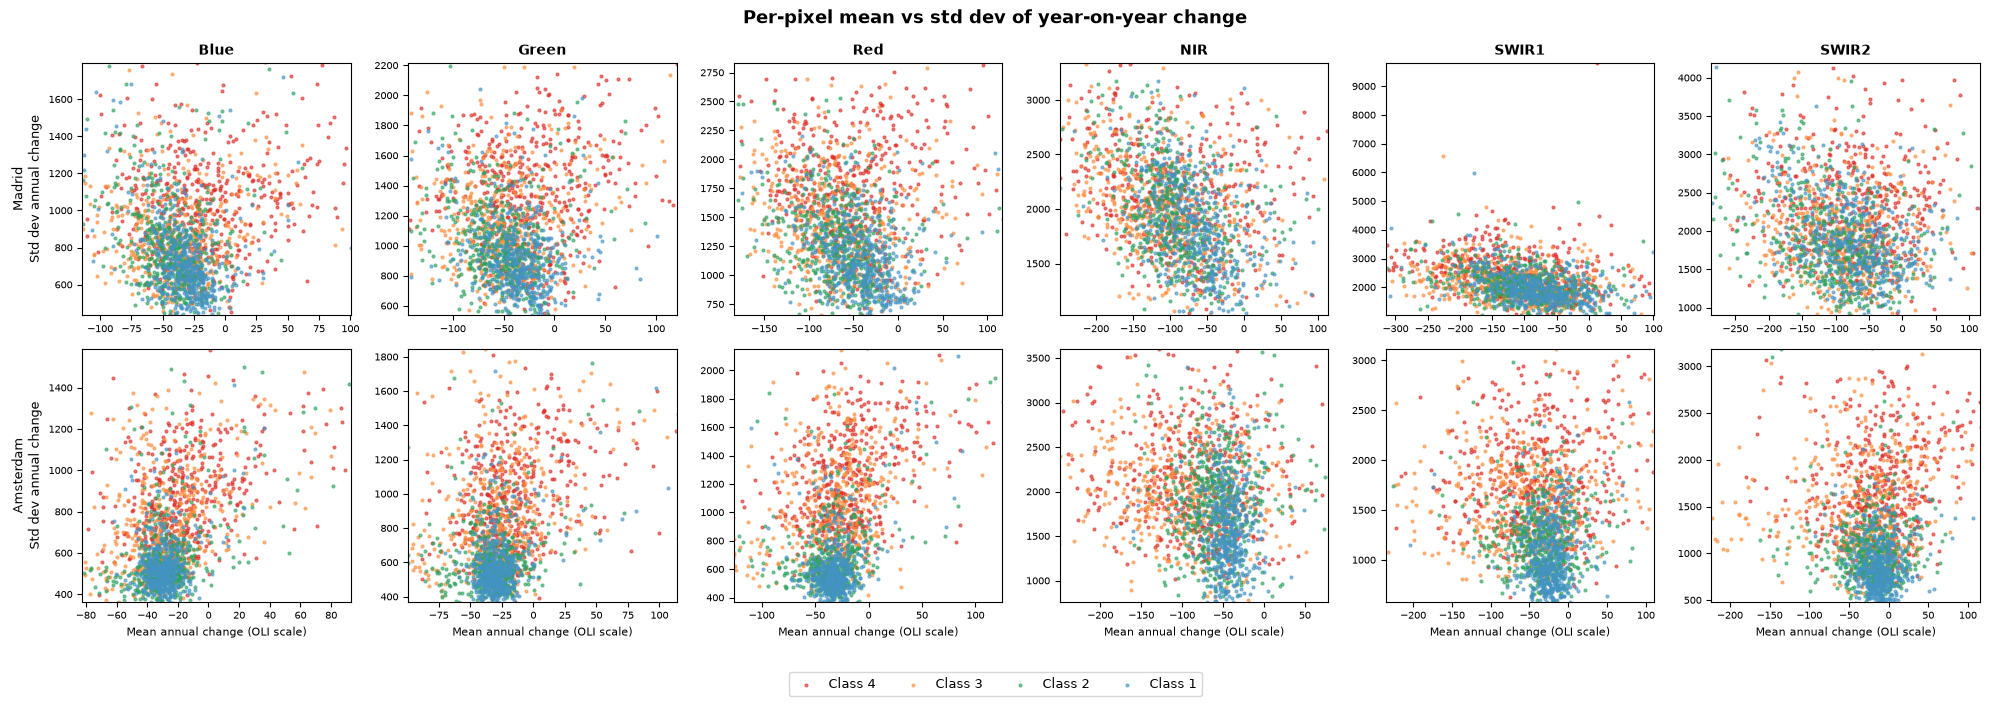

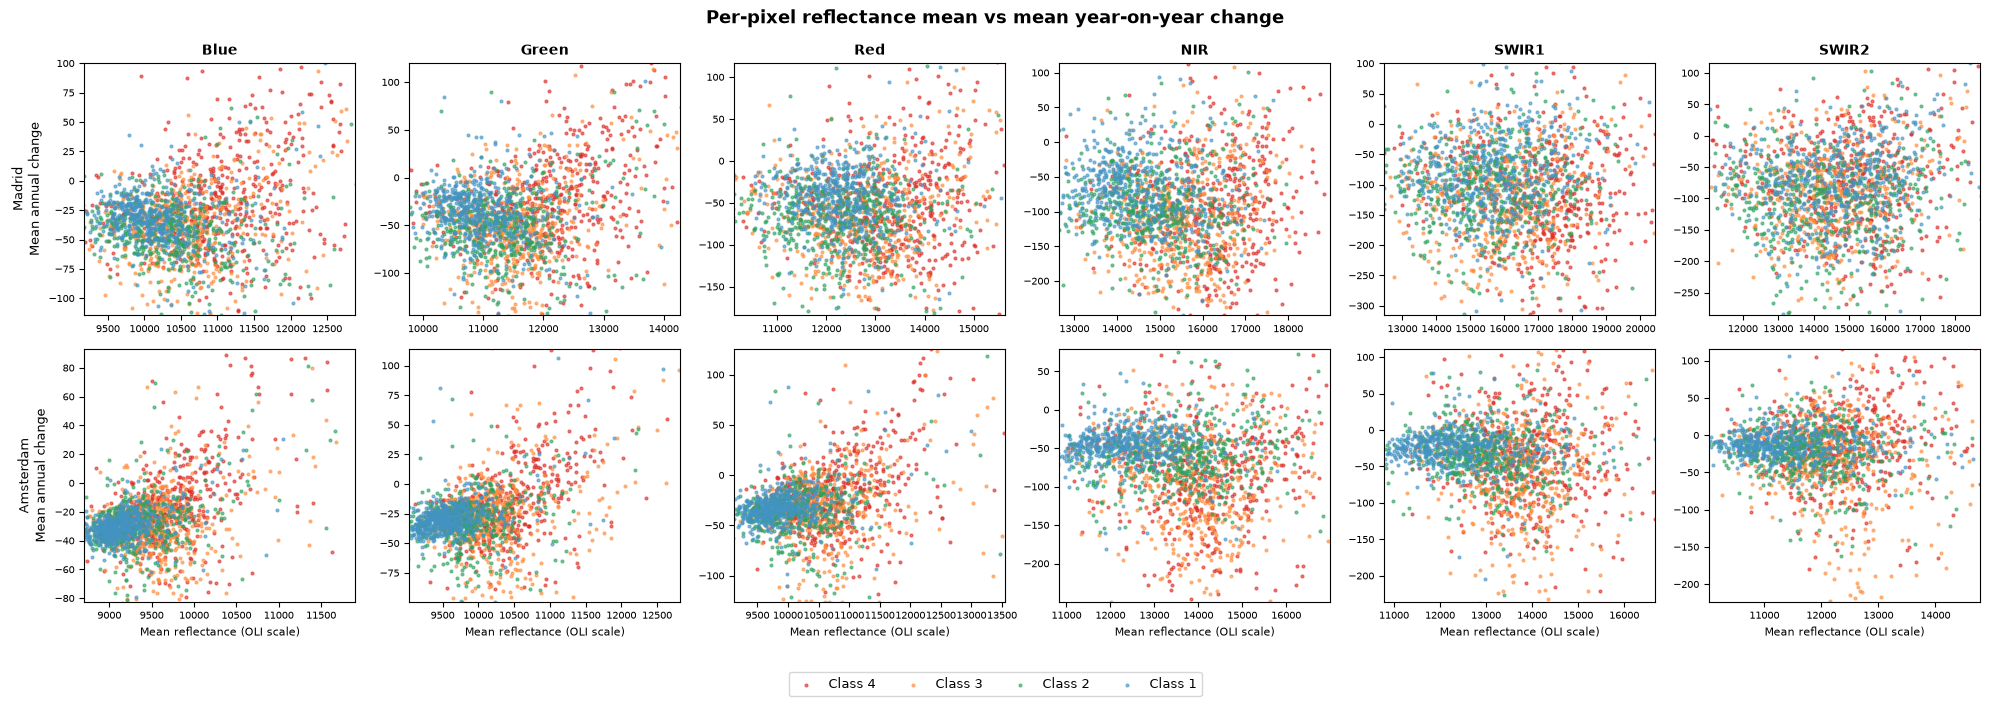

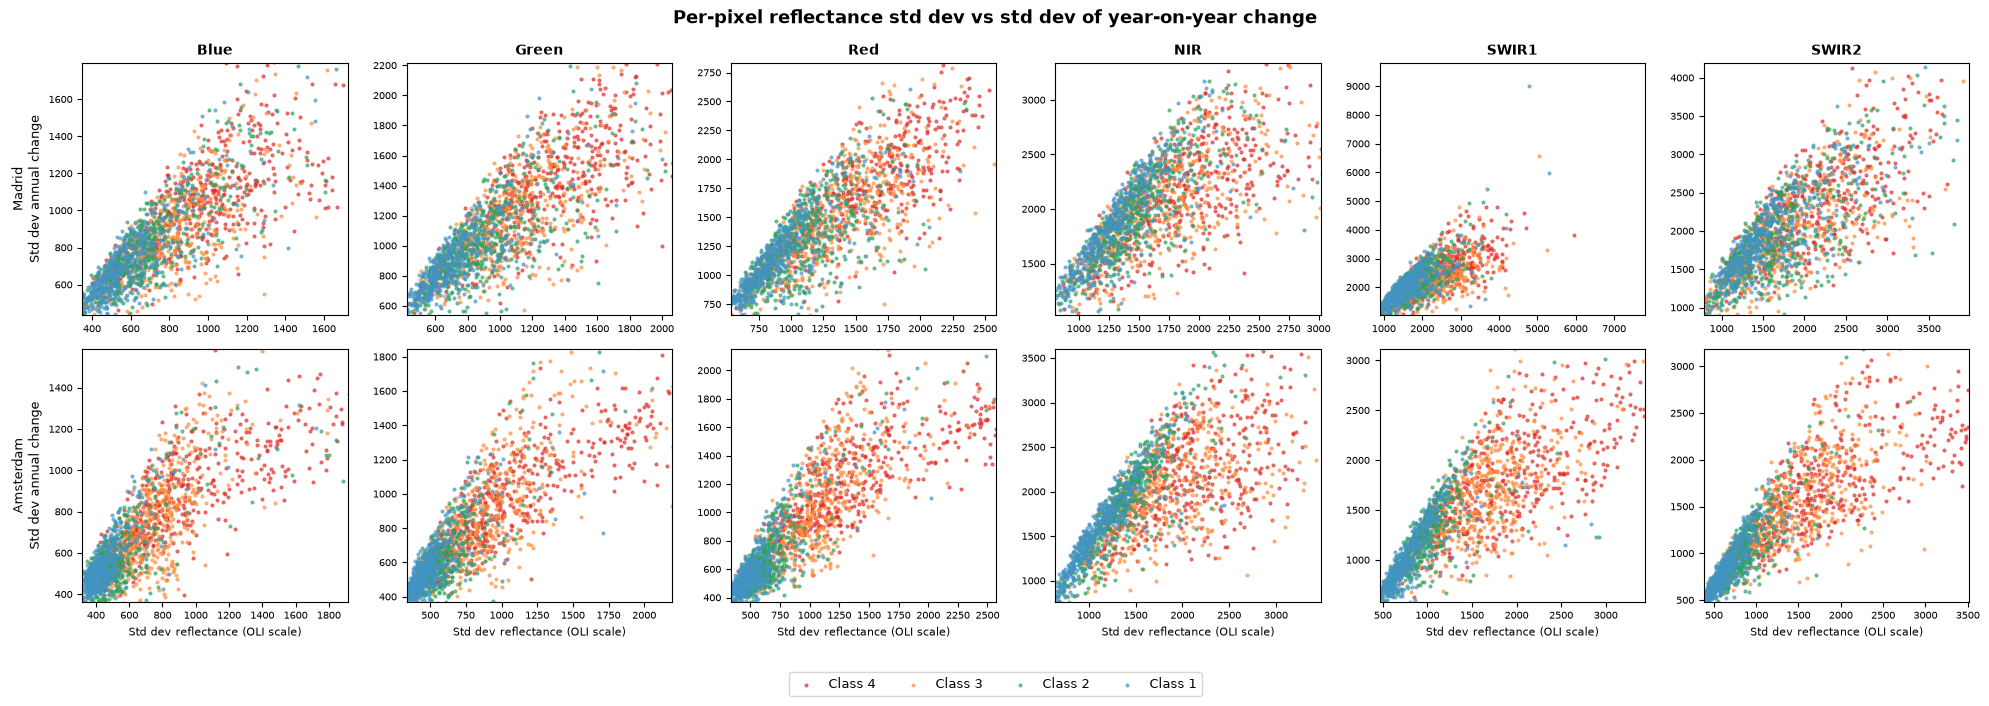

In [64]:
def plot_scatter_grid(xcol_fmt, ycol_fmt, suptitle, xlabel, ylabel, n_sample=500):
    fig, axes = plt.subplots(2, len(BASE_BANDS), figsize=(20, 7))
    rng = np.random.default_rng(42)
    for row, (city_name, flat, _) in enumerate(CITIES):
        ps = pixel_stats[city_name]
        for ci, band in enumerate(BASE_BANDS):
            ax   = axes[row, ci]
            xcol = xcol_fmt.format(band=band)
            ycol = ycol_fmt.format(band=band)
            xl   = np.percentile(ps[xcol].dropna(), [1, 99])
            yl   = np.percentile(ps[ycol].dropna(), [1, 99])
            for cls in [4, 3, 2, 1]:
                sub = ps[ps["age_class"] == cls][[xcol, ycol]].dropna()
                if len(sub) > n_sample:
                    idx = rng.choice(len(sub), n_sample, replace=False)
                    sub = sub.iloc[idx]
                lbl = f"Class {cls}" if (row == 0 and ci == 0) else ""
                ax.scatter(sub[xcol], sub[ycol],
                           color=CLASS_COLORS.get(cls, "grey"),
                           s=4, alpha=0.6, label=lbl)
            ax.set_xlim(xl); ax.set_ylim(yl)
            if row == 0:
                ax.set_title(band, fontweight="bold", fontsize=10)
            if ci == 0:
                ax.set_ylabel(city_name + "\n" + ylabel, fontsize=9)
            if row == 1:
                ax.set_xlabel(xlabel, fontsize=8)
            ax.tick_params(labelsize=7)
    handles, lbls = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, lbls, loc="lower center", ncol=4, fontsize=9,
               bbox_to_anchor=(0.5, -0.01))
    fig.suptitle(suptitle, fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

plot_scatter_grid("{band}_mean",   "{band}_std",
                  "Per-pixel mean vs std dev of reflectance",
                  "Mean reflectance (OLI scale)", "Std dev")
plot_scatter_grid("d_{band}_mean", "d_{band}_std",
                  "Per-pixel mean vs std dev of year-on-year change",
                  "Mean annual change (OLI scale)", "Std dev annual change")
plot_scatter_grid("{band}_mean",   "d_{band}_mean",
                  "Per-pixel reflectance mean vs mean year-on-year change",
                  "Mean reflectance (OLI scale)", "Mean annual change")
plot_scatter_grid("{band}_std",    "d_{band}_std",
                  "Per-pixel reflectance std dev vs std dev of year-on-year change",
                  "Std dev reflectance (OLI scale)", "Std dev annual change")

In [65]:
df_flat[BASE_BANDS].describe().round(1)

,Blue,Green,Red,NIR,SWIR1,SWIR2
count,3137920.0,3137920.0,3137920.0,3137920.0,3137920.0,3137920.0
mean,10532.4,11473.5,12618.9,15324.3,16036.4,14649.2
std,1089.6,1378.5,1710.2,2121.8,2780.6,2496.6
min,0.0,0.0,501.0,6834.0,6987.5,7292.8
25%,9791.9,10537.0,11458.9,13904.8,14196.7,12857.8
50%,10378.0,11266.0,12458.1,15241.5,15817.9,14441.1
75%,11089.3,12183.2,13577.2,16602.3,17578.5,16211.3
max,15000.0,38274.0,64388.1,66013.4,66655.6,66177.2


In [66]:
for city_name, flat, _ in CITIES:
    is_zero      = (flat[BASE_BANDS] == 0).any(axis=1)
    is_saturated = (flat[BASE_BANDS] == 65535).any(axis=1)
    n_corrupt    = (is_zero | is_saturated).sum()
    status = "clean" if n_corrupt == 0 else f"WARNING — {n_corrupt:,} corrupt rows"
    print(f"{city_name:12s}: {len(flat):,} rows — {status}")

Madrid      : 3,137,920 rows — WARNING — 23 corrupt rows
Amsterdam   : 1,049,960 rows — WARNING — 7 corrupt rows


In [67]:
corr_madrid = df_flat[BASE_BANDS].corr()

corr_madrid.round(3)

,Blue,Green,Red,NIR,SWIR1,SWIR2
Blue,1.000,0.956,0.896,0.529,0.622,0.676
Green,0.956,1.000,0.952,0.634,0.718,0.738
Red,0.896,0.952,1.000,0.628,0.804,0.833
NIR,0.529,0.634,0.628,1.000,0.727,0.556
SWIR1,0.622,0.718,0.804,0.727,1.000,0.899
SWIR2,0.676,0.738,0.833,0.556,0.899,1.000


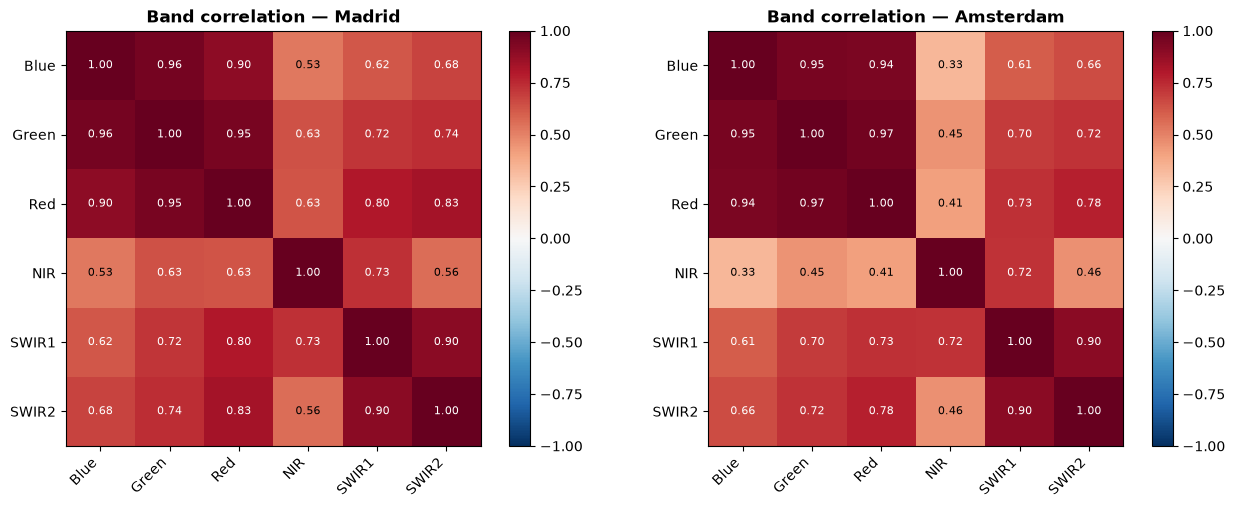

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
n = len(BASE_BANDS)
for ax, (city_name, flat, _) in zip(axes, CITIES):
    corr = flat[BASE_BANDS].corr().values
    im   = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(BASE_BANDS, rotation=45, ha='right')
    ax.set_yticks(range(n)); ax.set_yticklabels(BASE_BANDS)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f'{corr[i,j]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(corr[i,j]) > 0.6 else 'black')
    plt.colorbar(im, ax=ax)
    ax.set_title(f'Band correlation — {city_name}', fontweight='bold')
plt.tight_layout(); plt.show()


In [71]:
for name, df in [('Madrid', df), ('Amsterdam', df_ams)]:
    print(f'{name}: {df.shape[0]:,} rows x {df.shape[1]} columns')
    print(f'  Years:  {df["year"].min()}-{df["year"].max()}  ({df["year"].nunique()} distinct years)')
    print(f'  Pixels: {df.groupby(["px_key","py_key"]).ngroups:,} unique geographic pixels')
    print()


Madrid: 3,172,765 rows x 49 columns
  Years:  1984-2025  (42 distinct years)
  Pixels: 76,263 unique geographic pixels

Amsterdam: 1,062,877 rows x 49 columns
  Years:  1984-2025  (42 distinct years)
  Pixels: 25,992 unique geographic pixels



In [80]:
df_ams.to_parquet("amsterdam_data_saved.parquet", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [91]:
df.to_parquet("madrid_data_saved.parquet", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [92]:
DATA_DIR = './data'

df_madrid = pd.read_parquet(f'{DATA_DIR}/madrid_data_saved.parquet')
df_amsterdam = pd.read_parquet(f'{DATA_DIR}/amsterdam_data_saved.parquet')

for name, df in [('Madrid', df_madrid), ('Amsterdam', df_amsterdam)]:
    print(f'{name}: {df.shape[0]:,} rows x {df.shape[1]} columns')
    print(f'  Years:  {df["year"].min()}-{df["year"].max()}  ({df["year"].nunique()} distinct years)')
    print(f'  Pixels: {df.groupby(["px_key","py_key"]).ngroups:,} unique geographic pixels')
    print()

Madrid: 1,062,877 rows x 49 columns
  Years:  1984-2025  (42 distinct years)
  Pixels: 25,992 unique geographic pixels

Amsterdam: 1,062,877 rows x 49 columns
  Years:  1984-2025  (42 distinct years)
  Pixels: 25,992 unique geographic pixels



In [94]:
import pandas as pd

DATA_DIR = './data'

# Load the original datasets
df_madrid = pd.read_parquet(f'{DATA_DIR}/madrid_train.parquet')
df_amsterdam = pd.read_parquet(f'{DATA_DIR}/amsterdam_data.parquet')

# Verify the city information
for name, data in [('Madrid', df_madrid), ('Amsterdam', df_amsterdam)]:
    print(f"\n{name}")
    print("-" * 40)
    print("Shape:", data.shape)
    print("\nCity values:")
    print(data['city'].value_counts())
    print("\nUnique geographical pixels:",
          data.groupby(['px_key', 'py_key']).ngroups)


Madrid
----------------------------------------
Shape: (3172765, 48)

City values:
city
Madrid    3172765
Name: count, dtype: int64

Unique geographical pixels: 76263

Amsterdam
----------------------------------------
Shape: (1062877, 48)

City values:
city
Amsterdam    1062877
Name: count, dtype: int64

Unique geographical pixels: 25992


In [88]:
def assign_age_class(data, events=CLASS_EVENTS):
    out = data.copy()
    out['age_class'] = pd.NA
    for city, ev in events.items():
        mask = out['city'] == city
        if mask.any():
            bins = [-np.inf, ev, 1984, 2004, np.inf]
            out.loc[mask, 'age_class'] = pd.cut(
                out.loc[mask, 'weighted_mean_year'],
                bins=bins, labels=[1, 2, 3, 4]
            ).astype('Int64')
    return out

df_madrid    = assign_age_class(df_madrid)
df_amsterdam = assign_age_class(df_amsterdam)

for name, df in [('Madrid', df_madrid), ('Amsterdam', df_amsterdam)]:
    labels = CLASS_LABELS[name]
    pixels = df.drop_duplicates(['px_key', 'py_key'])
    print(f'{name} ({pixels["age_class"].notna().sum():,} labelled pixels):')
    for cls in [1, 2, 3, 4]:
        n = (pixels['age_class'] == cls).sum()
        print(f'  Class {cls} ({labels[int(cls)]}): {n:,}')
    print()


Madrid (25,992 labelled pixels):
  Class 1 (Pre-1960): 7,568
  Class 2 (1960-1984): 8,802
  Class 3 (1984-2004): 6,745
  Class 4 (2004-2024): 2,877

Amsterdam (25,992 labelled pixels):
  Class 1 (Pre-1945): 7,568
  Class 2 (1945-1984): 8,802
  Class 3 (1984-2004): 6,745
  Class 4 (2004-2024): 2,877



In [89]:
def assign_age_class(data, events=CLASS_EVENTS):
    out = data.copy()
    out['age_class'] = pd.NA
    for city, ev in events.items():
        mask = out['city'] == city
        if mask.any():
            bins = [-np.inf, ev, 1984, 2004, np.inf]
            out.loc[mask, 'age_class'] = pd.cut(
                out.loc[mask, 'weighted_mean_year'],
                bins=bins, labels=[1, 2, 3, 4]
            ).astype('Int64')
    return out

df_madrid    = assign_age_class(df_madrid)
df_amsterdam = assign_age_class(df_amsterdam)

for name, df in [('Madrid', df_madrid), ('Amsterdam', df_amsterdam)]:
    labels = CLASS_LABELS[name]
    pixels = df.drop_duplicates(['px_key', 'py_key'])
    print(f'{name} ({pixels["age_class"].notna().sum():,} labelled pixels):')
    for cls in [1, 2, 3, 4]:
        n = (pixels['age_class'] == cls).sum()
        print(f'  Class {cls} ({labels[int(cls)]}): {n:,}')
    print()

Madrid (25,992 labelled pixels):
  Class 1 (Pre-1960): 7,568
  Class 2 (1960-1984): 8,802
  Class 3 (1984-2004): 6,745
  Class 4 (2004-2024): 2,877

Amsterdam (25,992 labelled pixels):
  Class 1 (Pre-1945): 7,568
  Class 2 (1945-1984): 8,802
  Class 3 (1984-2004): 6,745
  Class 4 (2004-2024): 2,877



In [90]:
def get_best_obs_band(data, band):
    col = np.full(len(data), np.nan)
    for slot in [1, 2, 3]:
        bc = f'{band}_{slot}'
        qc = f'qa_valid_{slot}'
        if bc not in data.columns or qc not in data.columns:
            continue
        valid = data[qc].fillna(False).values
        col = np.where(np.isnan(col) & valid, data[bc].fillna(np.nan).values, col)
    return col

def make_flat_view(data):
    keep = [c for c in ['pixel_id', 'city', 'year', 'px_key', 'py_key',
                        'weighted_mean_year', 'age_class']
            if c in data.columns]
    out = data[keep].copy()
    for band in BASE_BANDS:
        out[band] = get_best_obs_band(data, band)
    out = out.dropna(subset=BASE_BANDS)
    n_before = len(out)
    out = out[out['Blue'] <= BLUE_MAX].copy()
    removed = n_before - len(out)
    if removed:
        city = data['city'].iloc[0] if 'city' in data.columns else ''
        print(f'  [{city}] Removed {removed:,} haze-contaminated rows (Blue > {BLUE_MAX:,})')
    return out

print('Flattening observations...')
flat_madrid    = make_flat_view(df_madrid)
flat_amsterdam = make_flat_view(df_amsterdam)

for name, flat in [('Madrid', flat_madrid), ('Amsterdam', flat_amsterdam)]:
    n_pix = flat.groupby(['px_key', 'py_key']).ngroups
    print(f'{name}: {len(flat):,} valid pixel-year rows, {n_pix:,} unique pixels')

# ── Period coverage indicators ─────────────────────────────────────────────────
# Computed NOW, before gap-filling, while the original observed-year pattern is intact.
EARLY_CUTOFF = 2003   # 1984-2003: first ~20 years of Landsat record
LATE_START   = 2004   # 2004+:     most recent ~20 years
PID          = ['px_key', 'py_key']

def period_coverage(flat):
    pixels    = flat[PID].drop_duplicates()
    has_early = flat[flat['year'] <= EARLY_CUTOFF].drop_duplicates(PID).assign(has_early_data=1.0)
    has_late  = flat[flat['year'] >= LATE_START].drop_duplicates(PID).assign(has_late_data=1.0)
    ind = (pixels
           .merge(has_early[PID + ['has_early_data']], on=PID, how='left')
           .merge(has_late[PID  + ['has_late_data']],  on=PID, how='left')
           .fillna(0.0))
    return ind

indicators_madrid    = period_coverage(flat_madrid)
indicators_amsterdam = period_coverage(flat_amsterdam)

for name, ind in [('Madrid', indicators_madrid), ('Amsterdam', indicators_amsterdam)]:
    print(f'{name}: {(ind["has_early_data"]==0).sum()} pixels with no early data, '
          f'{(ind["has_late_data"]==0).sum()} with no late data')


Flattening observations...
  [Amsterdam] Removed 12,917 haze-contaminated rows (Blue > 15,000)
  [Amsterdam] Removed 12,917 haze-contaminated rows (Blue > 15,000)
Madrid: 1,049,960 valid pixel-year rows, 25,992 unique pixels
Amsterdam: 1,049,960 valid pixel-year rows, 25,992 unique pixels
Madrid: 0 pixels with no early data, 7 with no late data
Amsterdam: 0 pixels with no early data, 7 with no late data
